# ETS Machine Learning II — Prediksi RNFL 12 Clock-Hour dari Fundus

**Tujuan:** memperkirakan ketebalan RNFL 12 sektor dari foto fundus untuk membantu analisis saraf optik. Satuan target dan metrik adalah µm. Ini proyek eksperimen, bukan alat diagnosis klinis.

Notebook ini meneruskan replikasi Chen et al. dengan empat komponen sesuai rubrik ETS: **akuisisi/wrangling data**, **augmentasi citra**, **ensemble learning**, dan **reinforcement learning berbentuk contextual-free multi-armed bandit** untuk memilih strategi akuisisi data berlabel. Evaluasi utama memakai 5-fold GroupKFold pasien. Validasi reward bandit dipisah dari fold luar sehingga label fold luar tidak dipakai untuk memilih data.

Baseline Chen: OLS, Ridge, Lasso, ElasticNet. Model ETS membandingkan Ridge, ExtraTrees, gabungan rata-rata keduanya, dan ensemble dengan augmentasi fotometrik. Kurva akuisisi membandingkan kebijakan bandit UCB1 dengan pemilihan pasien acak pada anggaran label yang sama.

Paper acuan: Chen et al., *Independent Evaluation of RETFound Foundation Model’s Performance on Optic Nerve Analysis Using Fundus Photography*, Ophthalmology Science (2025), DOI: https://doi.org/10.1016/j.xops.2025.100720.

**Batas pairing:** tanggal foto tidak tersedia; kriteria selang 6 bulan dari paper belum dapat diverifikasi. Audit pasangan dan jumlah data yang tersisih diekspor.

## 1. Input dan cara menjalankan di Kaggle

1. Buat **Kaggle Dataset** privat yang berisi `rnfl_metadata_lengkap.csv` dan folder `fundus/` dengan foto sesuai metadata. Tambahkan dataset itu melalui **Add Input** di notebook Kaggle. Tidak perlu menaruh CSV atau foto di `/kaggle/working`.
2. Opsional: tambahkan laporan OCT sesuai `oct_filename` untuk QC, dan `fundus_oct_pairs_reviewed.csv` bila pasangan foto telah diperiksa manual.
3. Opsional untuk replikasi Chen: tambahkan dataset berisi kode resmi `RETFound_official/models_vit.py` bersama folder `util/`, checkpoint **`RETFound_mae_natureCFP.pth`**, dan paket `timm` yang kompatibel. Aktifkan GPU untuk ekstraksi RETFound. [Kode resmi](https://github.com/rmaphoh/RETFound) dan [checkpoint CFP](https://huggingface.co/YukunZhou/RETFound_mae_natureCFP) harus diunggah sebagai Kaggle Input sesuai izin penggunaannya. Checkpoint OCT tidak cocok untuk foto fundus.
4. Jalankan **Run All**. Hasil CSV dan fitur tersimpan di `/kaggle/working/rnfl_ets_outputs/` dan dapat diunduh dari tab Output. Internet Kaggle tidak diperlukan setelah semua input terpasang.

**Mode tanpa RETFound:** notebook memakai fitur gambar deterministik (thumbnail abu-abu, histogram warna, statistik warna), sehingga pipeline ETS tetap dapat dijalankan hanya dengan CSV dan foto. Angka pada mode ini adalah baseline eksploratif, **bukan** hasil replikasi RETFound/Chen. `feature_source` dicatat pada output.

Foto fundus dipertahankan orientasinya. Augmentasi hanya mengubah kecerahan, kontras, dan saturasi secara ringan. Citra validasi dan target RNFL tidak diaugmentasi. Transformasi kedua dihitung untuk seluruh citra demi cache fitur, tetapi hanya baris **train** dari tiap fold yang dipakai untuk fit model.

In [1]:
from pathlib import Path
import os, re, sys, json, math, warnings, random
import numpy as np
try:
    import torch
    from torch import nn
    from torch.utils.data import Dataset, DataLoader
    from torchvision import transforms
    from torchvision.transforms import InterpolationMode
except (ImportError, RuntimeError) as exc:
    torch = None
    print("PyTorch/torchvision tidak tersedia; fitur gambar sederhana akan dipakai:", exc)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps, ImageEnhance
from IPython.display import display

SEED = 42
N_FOLDS = 5
IMAGE_SIZE = 224
BATCH_SIZE = 8
NUM_WORKERS = 2
INPUT_ROOT = Path("/kaggle/input") if Path("/kaggle/input").exists() else Path.cwd() / "input"
OUTPUT_DIR = (Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()) / "rnfl_ets_outputs"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu") if torch else None
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
sns.set_theme(style="whitegrid", context="notebook")

image_exts = {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
csv_hits = sorted(INPUT_ROOT.rglob("rnfl_metadata_lengkap.csv"))
if not csv_hits:
    raise FileNotFoundError(f"Tidak menemukan rnfl_metadata_lengkap.csv di {INPUT_ROOT}. Tambahkan Kaggle Input sesuai bagian 1.")
CSV_PATH = csv_hits[0]
fundus_hits = []
for p in INPUT_ROOT.rglob("fundus"):
    if p.is_dir() and any(x.is_file() and x.suffix.lower() in image_exts for x in p.rglob("*")):
        fundus_hits.append(p)
if not fundus_hits:
    raise FileNotFoundError(f"Folder fundus berisi citra tidak ditemukan di {INPUT_ROOT}.")
FUNDUS_DIR = sorted(fundus_hits, key=lambda p: len(p.parts))[0]
oct_image_paths = [p for p in INPUT_ROOT.rglob("*") if p.is_file() and p.suffix.lower() in image_exts and p.name.lower().startswith("oct_")]
oct_image_index = {}
for p in sorted(oct_image_paths): oct_image_index.setdefault(p.name.lower(), []).append(p)
PAIR_OVERRIDE_HITS = sorted(INPUT_ROOT.rglob("fundus_oct_pairs_reviewed.csv"))
PAIR_OVERRIDE_PATH = PAIR_OVERRIDE_HITS[0] if PAIR_OVERRIDE_HITS else None
MODEL_CODE_HITS = sorted(INPUT_ROOT.rglob("models_vit.py"))
WEIGHT_HITS = sorted(p for p in INPUT_ROOT.rglob("*.pth") if "retfound" in p.name.lower() and ("cfp" in p.name.lower() or "fundus" in p.name.lower()))
print("Metadata:", CSV_PATH, "| Fundus:", FUNDUS_DIR)
print("OCT:", len(oct_image_paths), "| Pairing manual:", PAIR_OVERRIDE_PATH)
print("Kode RETFound:", MODEL_CODE_HITS[:2], "| Bobot CFP:", WEIGHT_HITS[:2])
print("Output:", OUTPUT_DIR, "| Device:", DEVICE)

Metadata: /kaggle/input/datasets/septiadiniarifta/rnfl-fundus-sectors/rnfl_metadata_lengkap.csv | Fundus: /kaggle/input/datasets/septiadiniarifta/rnfl-fundus-sectors/fundus
OCT: 0 | Pairing manual: None
Kode RETFound: [PosixPath('/kaggle/input/datasets/septiadiniarifta/retfound/RETFound_official/models_vit.py')] | Bobot CFP: [PosixPath('/kaggle/input/datasets/septiadiniarifta/retfound/RETFound_official/RETFound_mae_natureCFP.pth')]
Output: /kaggle/working/rnfl_ets_outputs | Device: cuda


## 2. Baca metadata dan audit pasangan citra-label

Setiap baris mewakili satu mata/OCT. Pasangan dibentuk dari **ID pasien + laterality**. Notebook memilih satu foto per kombinasi ID pasien + sisi mata. Kecocokan suffix OCT-fundus yang unik diprioritaskan; jika tidak ditemukan, dipilih kandidat valid pertama secara alfabetis. Foto yang sama digunakan untuk seluruh baris RNFL pada pasien-mata itu, sehingga baris tidak dikeluarkan hanya karena ada beberapa kandidat.

Paper Chen memilih pasangan foto fundus dan OCT pada mata yang sama dengan jarak tanggal paling lama 6 bulan, lalu tanggal terdekat. CSV kita tidak memiliki tanggal foto fundus, jadi hubungan tanggal belum bisa dipastikan otomatis. Gambar OCT dapat ditampilkan berdampingan dengan fundus untuk pemeriksaan manual.



In [2]:
df_raw = pd.read_csv(CSV_PATH, dtype={"patient_id": str})
df = df_raw.copy()
df["patient_id"] = df["patient_id"].astype(str).str.strip()
df["laterality"] = df["laterality"].astype(str).str.upper().str.strip()
sector_cols = [f"rnfl_clock_{i}" for i in range(12)]
missing_cols = [c for c in ["patient_id","laterality","diagnosis","fundus_filename","oct_filename",*sector_cols] if c not in df.columns]
if missing_cols:
    raise ValueError(f"Kolom CSV tidak lengkap: {missing_cols}")
df[sector_cols] = df[sector_cols].apply(pd.to_numeric, errors="coerce")
df["diagnosis"] = df["diagnosis"].astype(str).str.lower().str.strip()

# Index semua foto dengan identitas pasien dan sisi mata yang dibaca dari nama file fff_*_<ID>_<r/l>_*
fundus_paths = [p for p in FUNDUS_DIR.rglob("*") if p.is_file() and p.suffix.lower() in image_exts]
fundus_index = {}
for p in fundus_paths:
    m = re.match(r"fff_[01]_(\d+)_([rl])_", p.name, flags=re.I)
    if m:
        side = {"r":"OD", "l":"OS"}[m.group(2).lower()]
        file_pid = m.group(1).lstrip("0") or "0"
        fundus_index.setdefault((file_pid, side), []).append(p)

# Override manual (jika tersedia) mengikat exact patient+eye+OCT ke satu foto.
manual_pairs = {}
if PAIR_OVERRIDE_PATH:
    pair_df = pd.read_csv(PAIR_OVERRIDE_PATH, dtype=str).fillna("")
    needed = {"patient_id","laterality","oct_filename","fundus_filename"}
    if not needed.issubset(pair_df.columns):
        raise ValueError(f"Pairing manual harus memuat kolom {sorted(needed)}")
    for _, r in pair_df.iterrows():
        manual_pairs[(r.patient_id.strip(), r.laterality.upper().strip(), Path(r.oct_filename).name)] = r.fundus_filename.strip()

audit_rows = []
selected_paths = []
# Pilih satu foto secara konsisten untuk setiap pasien + mata; gunakan lagi untuk semua baris RNFL mata tersebut.
chosen_fundus_by_eye = {}
for _, r in df.iterrows():
    pid, eye = r["patient_id"], r["laterality"]
    raw_names = [x.strip() for x in str(r["fundus_filename"]).split(";") if x.strip() and x.strip().lower() not in {"nan","0"}]
    candidates = []
    valid_metadata_refs = 0
    for name in raw_names:
        basename = Path(name).name
        hit = next((p for p in fundus_paths if p.name == basename), None)
        match = re.match(r"fff_[01]_(\d+)_([rl])_", basename, flags=re.I)
        if hit is not None and match:
            file_pid = match.group(1).lstrip("0") or "0"
            row_pid = pid.lstrip("0") or "0"
            file_eye = {"r":"OD", "l":"OS"}[match.group(2).lower()]
            if file_pid == row_pid and file_eye == eye:
                valid_metadata_refs += 1
                if hit not in candidates:
                    candidates.append(hit)
    n_invalid_metadata_refs = len(raw_names) - valid_metadata_refs
    # Jika metadata kosong/typo, fallback ke nama file yang cocok dengan patient_id + sisi.
    if not candidates:
        pid_key = pid.lstrip("0") or "0"
        candidates = sorted(fundus_index.get((pid_key, eye), []))
    oct_name = Path(str(r["oct_filename"])).name
    oct_match = re.match(r"oct_[01]_\d+_[rlu]_(.*)\.[^.]+$", oct_name, flags=re.I)
    oct_suffix = oct_match.group(1).lower() if oct_match else ""
    suffix_hits = []
    if oct_suffix:
        for candidate in candidates:
            fm = re.match(r"fff_[01]_\d+_[rl]_(.*)\.[^.]+$", candidate.name, flags=re.I)
            if fm and fm.group(1).lower() == oct_suffix:
                suffix_hits.append(candidate)
    suffix_suggestion = suffix_hits[0] if len(suffix_hits) == 1 else None
    oct_matches = oct_image_index.get(oct_name.lower(), [])
    oct_path = oct_matches[0] if len(oct_matches) == 1 else None
    key = (pid, eye, oct_name)
    override = manual_pairs.get(key, "")
    chosen = next((p for p in fundus_paths if p.name == Path(override).name), None) if override else None
    if override and chosen is None:
        raise FileNotFoundError(f"Foto di pairing manual tidak ditemukan: {override}")
    if chosen is not None:
        mm = re.match(r"fff_[01]_(\d+)_([rl])_", chosen.name, flags=re.I)
        valid_override = bool(mm) and (mm.group(1).lstrip("0") or "0") == (pid.lstrip("0") or "0") and {"r":"OD","l":"OS"}[mm.group(2).lower()] == eye
        if not valid_override:
            raise ValueError(f"Pairing manual tidak cocok dengan patient_id/laterality: {key} -> {chosen.name}")
    eye_key = (pid.lstrip("0") or "0", eye)
    if eye_key in chosen_fundus_by_eye:
        # Satu fundus per patient_id + laterality: jangan buang baris RNFL hanya
        # karena ada beberapa foto kandidat; pakai foto yang sudah dipilih.
        chosen = chosen_fundus_by_eye[eye_key]
        selection = "reuse_patient_eye_selected_fundus"
    elif chosen is not None:
        selection = "manual_reviewed_patient_eye"
        chosen_fundus_by_eye[eye_key] = chosen
    elif suffix_suggestion is not None:
        chosen = suffix_suggestion
        selection = "suffix_match_selected_for_patient_eye"
        chosen_fundus_by_eye[eye_key] = chosen
    elif candidates:
        # Jika tidak ada suffix OCT-fundus yang cocok, pilih nama file pertama
        # secara alfabetis agar hasilnya deterministik dan tidak acak.
        chosen = sorted(candidates, key=lambda p: p.name.lower())[0]
        selection = "first_sorted_candidate_selected_for_patient_eye"
        chosen_fundus_by_eye[eye_key] = chosen
    else:
        selection = "unmatched_no_fundus"
    selected_paths.append(chosen)
    audit_rows.append({
        "patient_id": pid, "laterality": eye, "diagnosis": r["diagnosis"],
        "oct_filename": r["oct_filename"], "oct_path": str(oct_path) if oct_path else "",
        "oct_path_match_count": len(oct_matches), "oct_filename_suffix": oct_suffix,
        "metadata_fundus_filename": r["fundus_filename"],
        "suffix_match_candidate_count": len(suffix_hits),
        "suggested_fundus_filename_by_suffix": suffix_suggestion.name if suffix_suggestion else "",
        "candidate_count": len(candidates),
        "n_invalid_metadata_refs": n_invalid_metadata_refs,
        "candidate_filenames": ";".join(p.name for p in candidates),
        "selected_fundus_filename": chosen.name if chosen else "",
        "selection_basis": selection if chosen else "unmatched"
    })

df["fundus_path"] = selected_paths
pair_audit = pd.DataFrame(audit_rows)
df["oct_path"] = pair_audit["oct_path"].replace("", np.nan)
pair_audit.to_csv(OUTPUT_DIR / "fundus_oct_pair_audit.csv", index=False)
print("Baris metadata:", len(df))
print("Pasien unik:", df.patient_id.nunique())
print("Foto fundus ditemukan:", int(df.fundus_path.notna().sum()), "/", len(df))
print("Baris dengan >1 kandidat foto:", int((pair_audit.candidate_count > 1).sum()))
print("Baris dengan suffix OCT-fundus sama (petunjuk, bukan validasi tanggal):", int((pair_audit.suffix_match_candidate_count == 1).sum()))
print("Baris tanpa foto terpilih:", int(df.fundus_path.isna().sum()))
print("Foto unik terpilih (pasien-mata):", len(chosen_fundus_by_eye))
selected_eye_pairs = pair_audit.loc[pair_audit.selected_fundus_filename.ne(""), ["patient_id", "laterality"]].drop_duplicates()
bilateral_n = selected_eye_pairs.groupby("patient_id")["laterality"].nunique().ge(2).sum()
print("Pasien dengan OD dan OS terpilih:", int(bilateral_n))
print("OD dan OS diperlakukan sebagai sampel mata terpisah; keduanya tetap satu grup pasien saat split.")
print("Baris RNFL yang memakai foto pilihan pasien-mata:", int(pair_audit.selection_basis.isin(["reuse_patient_eye_selected_fundus", "first_sorted_candidate_selected_for_patient_eye", "suffix_match_selected_for_patient_eye", "manual_reviewed_patient_eye"]).sum()))
print("OCT report yang ditemukan tepat satu:", int((pair_audit.oct_path_match_count == 1).sum()))
print("Baris dengan label sektor lengkap:", int(df[sector_cols].notna().all(axis=1).sum()))
print("Nilai RNFL nol:", int((df[sector_cols] == 0).sum().sum()))
display(pair_audit.head(12))
pair_template = pair_audit[["patient_id","laterality","oct_filename"]].copy()
pair_template["fundus_filename"] = pair_audit["suggested_fundus_filename_by_suffix"].where(
    pair_audit["suggested_fundus_filename_by_suffix"].ne(""), pair_audit["selected_fundus_filename"])
pair_template["selection_suggestion"] = pair_audit["selection_basis"]
pair_template.to_csv(OUTPUT_DIR / "fundus_oct_pairing_template.csv", index=False)
print("Audit:", OUTPUT_DIR / "fundus_oct_pair_audit.csv")
print("Template pairing manual:", OUTPUT_DIR / "fundus_oct_pairing_template.csv")


Baris metadata: 175
Pasien unik: 90
Foto fundus ditemukan: 154 / 175
Baris dengan >1 kandidat foto: 105
Baris dengan suffix OCT-fundus sama (petunjuk, bukan validasi tanggal): 35
Baris tanpa foto terpilih: 21
Foto unik terpilih (pasien-mata): 153
Pasien dengan OD dan OS terpilih: 69
OD dan OS diperlakukan sebagai sampel mata terpisah; keduanya tetap satu grup pasien saat split.
Baris RNFL yang memakai foto pilihan pasien-mata: 154
OCT report yang ditemukan tepat satu: 0
Baris dengan label sektor lengkap: 173
Nilai RNFL nol: 5


/tmp/ipykernel_23/1816541181.py:118: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["oct_path"] = pair_audit["oct_path"].replace("", np.nan)


,patient_id,laterality,diagnosis,oct_filename,oct_path,oct_path_match_count,oct_filename_suffix,metadata_fundus_filename,suffix_match_candidate_count,suggested_fundus_filename_by_suffix,candidate_count,n_invalid_metadata_refs,candidate_filenames,selected_fundus_filename,selection_basis
0,100287,OS,glaucoma,oct_1_100287_l_).jpg,,0,),fff_1_100287_l_).jpg,1,fff_1_100287_l_).jpg,1,0,fff_1_100287_l_).jpg,fff_1_100287_l_).jpg,suffix_match_selected_for_patient_eye
1,100287,OD,glaucoma,oct_1_100287_r_).jpg,,0,),fff_1_100287_r_).jpg,1,fff_1_100287_r_).jpg,1,0,fff_1_100287_r_).jpg,fff_1_100287_r_).jpg,suffix_match_selected_for_patient_eye
2,10207,OS,glaucoma,oct_1_10207_r_a.jpg,,0,a,fff_1_10207_l_1.jpg,0,,1,0,fff_1_10207_l_1.jpg,fff_1_10207_l_1.jpg,first_sorted_candidate_selected_for_patient_eye
3,10207,OD,glaucoma,oct_1_10207_r_a.jpg,,0,a,fff_1_10207_r_1.jpg;fff_1_10207_r_2.jpg,0,,2,0,fff_1_10207_r_1.jpg;fff_1_10207_r_2.jpg,fff_1_10207_r_1.jpg,first_sorted_candidate_selected_for_patient_eye
4,102473,OS,glaucoma,oct_1_102473_l_a.jpg,,0,a,fff_1_102473_l_a.jpg,1,fff_1_102473_l_a.jpg,1,0,fff_1_102473_l_a.jpg,fff_1_102473_l_a.jpg,suffix_match_selected_for_patient_eye
5,102473,OD,glaucoma,oct_1_102473_r_a.jpg,,0,a,fff_1_102473_r_a.jpg,1,fff_1_102473_r_a.jpg,1,0,fff_1_102473_r_a.jpg,fff_1_102473_r_a.jpg,suffix_match_selected_for_patient_eye
6,104166,OS,glaucoma,oct_1_104166_l_i.jpg,,0,i,fff_1_104166_l_1.jpg;fff_1_104166_l_2.jpg;fff_...,0,,3,0,fff_1_104166_l_1.jpg;fff_1_104166_l_2.jpg;fff_...,fff_1_104166_l_1.jpg,first_sorted_candidate_selected_for_patient_eye
7,104166,OD,glaucoma,oct_1_104166_r_i.jpg,,0,i,fff_1_104166_r_1.jpg;fff_1_104166_r_2.jpg;fff_...,0,,3,0,fff_1_104166_r_1.jpg;fff_1_104166_r_2.jpg;fff_...,fff_1_104166_r_1.jpg,first_sorted_candidate_selected_for_patient_eye
8,105821,OS,glaucoma,oct_1_105821_r_s.jpg,,0,s,"fff_1_105821_l_3,jpg",0,,2,1,fff_1_105821_l_3.jpg;fff_1_105821_l_g.jpg,fff_1_105821_l_3.jpg,first_sorted_candidate_selected_for_patient_eye
9,105821,OD,glaucoma,oct_1_105821_r_s.jpg,,0,s,fff_1_105821_r_1.jpg;fff_1_105821_r_2.jpg;fff_...,0,,3,0,fff_1_105821_r_1.jpg;fff_1_105821_r_2.jpg;fff_...,fff_1_105821_r_1.jpg,first_sorted_candidate_selected_for_patient_eye


Audit: /kaggle/working/rnfl_ets_outputs/fundus_oct_pair_audit.csv
Template pairing manual: /kaggle/working/rnfl_ets_outputs/fundus_oct_pairing_template.csv


## 3. EDA kohort dan kualitas label

EDA meliputi diagnosis, laterality, kelengkapan label, rentang nilai, distribusi tiap sektor, serta nilai RNFL menurut sektor dan sisi mata. Baris tanpa semua 12 target atau tanpa citra tidak dapat masuk ke regresi multi-output; jumlah yang dikeluarkan dicatat.


Jumlah record per diagnosis:


,n
diagnosis,
glaucoma,97
normal,78


Record per laterality:


,n
laterality,
OD,89
OS,86


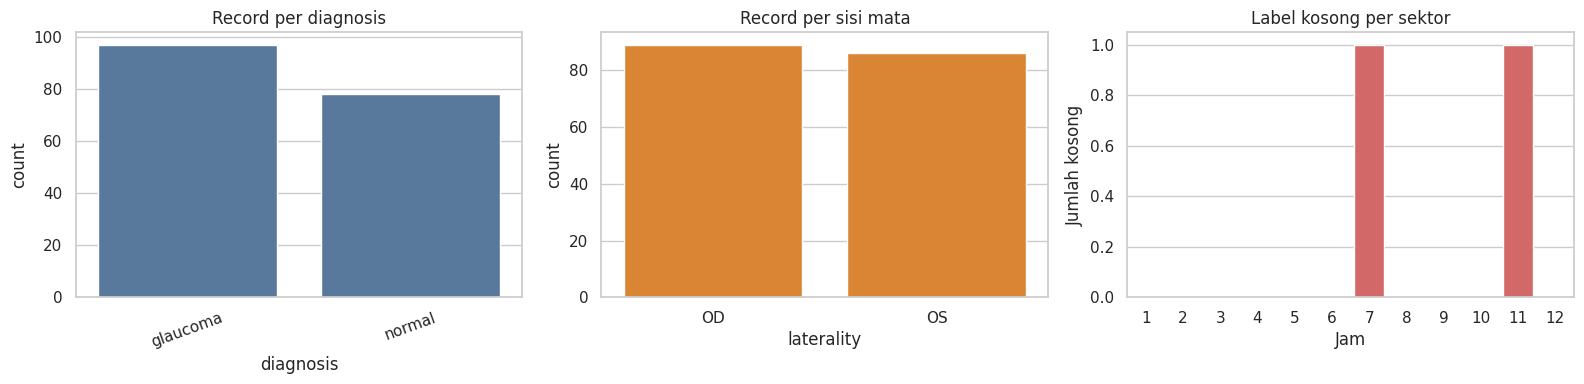

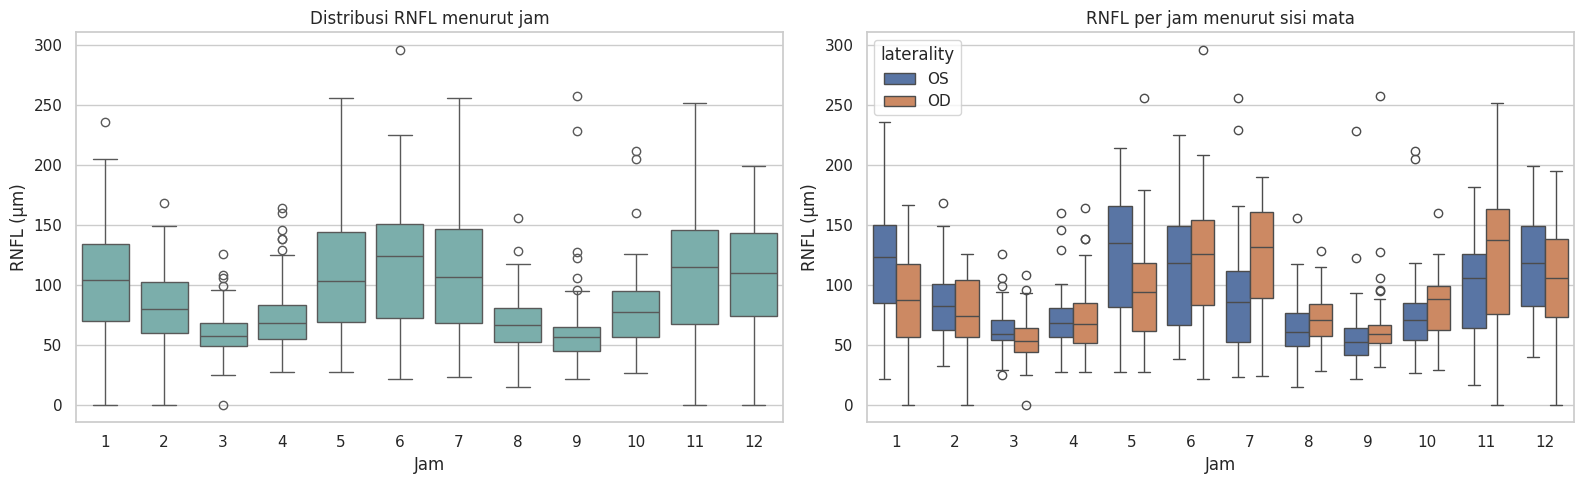

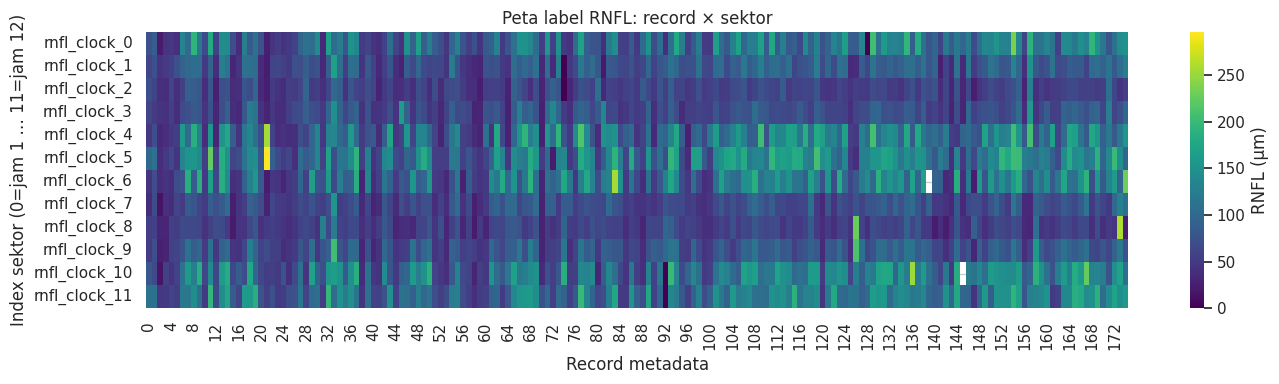

,sector,count,mean,std,min,25%,50%,75%,max
0,rnfl_clock_0,175.0,103.382857,43.372044,0.0,69.50,104.0,134.0,236.0
1,rnfl_clock_1,175.0,78.868571,28.132688,0.0,59.50,80.0,102.0,168.0
2,rnfl_clock_2,175.0,58.131429,17.687254,0.0,48.50,57.0,68.0,126.0
3,rnfl_clock_3,175.0,69.434286,24.578398,27.0,55.00,68.0,83.5,164.0
4,rnfl_clock_4,175.0,108.040000,48.887551,27.0,68.50,103.0,144.0,256.0
5,rnfl_clock_5,175.0,118.462857,48.680610,21.0,72.00,124.0,150.5,296.0
6,rnfl_clock_6,174.0,106.770115,48.523923,23.0,68.25,106.5,146.5,256.0
7,rnfl_clock_7,175.0,67.017143,21.925284,15.0,52.00,66.0,80.5,156.0
8,rnfl_clock_8,175.0,58.480000,26.129835,21.0,44.50,56.0,65.0,258.0
9,rnfl_clock_9,175.0,77.605714,28.459267,26.0,56.00,77.0,94.5,212.0


In [3]:
print("Jumlah record per diagnosis:")
display(df["diagnosis"].value_counts(dropna=False).rename_axis("diagnosis").to_frame("n"))
print("Record per laterality:")
display(df["laterality"].value_counts(dropna=False).rename_axis("laterality").to_frame("n"))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df, x="diagnosis", order=df.diagnosis.value_counts().index, ax=ax[0], color="#4C78A8")
ax[0].set_title("Record per diagnosis"); ax[0].tick_params(axis="x", rotation=20)
sns.countplot(data=df, x="laterality", order=["OD","OS"], ax=ax[1], color="#F58518")
ax[1].set_title("Record per sisi mata")
miss = df[sector_cols].isna().sum()
sns.barplot(x=np.arange(12)+1, y=miss.values, ax=ax[2], color="#E45756")
ax[2].set_title("Label kosong per sektor"); ax[2].set_xlabel("Jam"); ax[2].set_ylabel("Jumlah kosong")
plt.tight_layout(); plt.show()

long_targets = df.melt(id_vars=["patient_id","laterality","diagnosis"], value_vars=sector_cols,
                       var_name="sector", value_name="rnfl_um").dropna(subset=["rnfl_um"])
long_targets["clock_hour"] = long_targets["sector"].str.extract(r"(\d+)$").astype(int) + 1
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=long_targets, x="clock_hour", y="rnfl_um", ax=ax[0], color="#72B7B2")
ax[0].set_title("Distribusi RNFL menurut jam"); ax[0].set_xlabel("Jam"); ax[0].set_ylabel("RNFL (µm)")
sns.boxplot(data=long_targets, x="clock_hour", y="rnfl_um", hue="laterality", ax=ax[1])
ax[1].set_title("RNFL per jam menurut sisi mata"); ax[1].set_xlabel("Jam"); ax[1].set_ylabel("RNFL (µm)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(df[sector_cols].T, cmap="viridis", cbar_kws={"label":"RNFL (µm)"}, ax=ax)
ax.set_title("Peta label RNFL: record × sektor")
ax.set_xlabel("Record metadata"); ax.set_ylabel("Index sektor (0=jam 1 … 11=jam 12)")
plt.tight_layout(); plt.show()

display(df[sector_cols].describe().T.rename_axis("sector").reset_index())


## 4. Pairing fundus–OCT dan orientasi mata

Pasangan ditentukan dari ID pasien dan mata (`OD`/`OS`). Sel berikut memilih contoh yang tersedia untuk QC visual; hasil inspeksi perlu diperiksa pada dataset asli. Label `T/N/S/I` di laporan OCT, bila tersedia, membantu memeriksa orientasi. Tanpa laporan atau tanggal foto, kesesuaian temporal pasangan belum dapat dipastikan otomatis.

Notebook menormalkan urutan target jam RNFL OD mengikuti asumsi konvensi Chen (jam 3 temporal, jam 9 nasal). Foto fundus **tidak dibalik**. Periksa asumsi transformasi ini terhadap definisi kolom CSV sebelum hasil dijadikan klaim klinis.


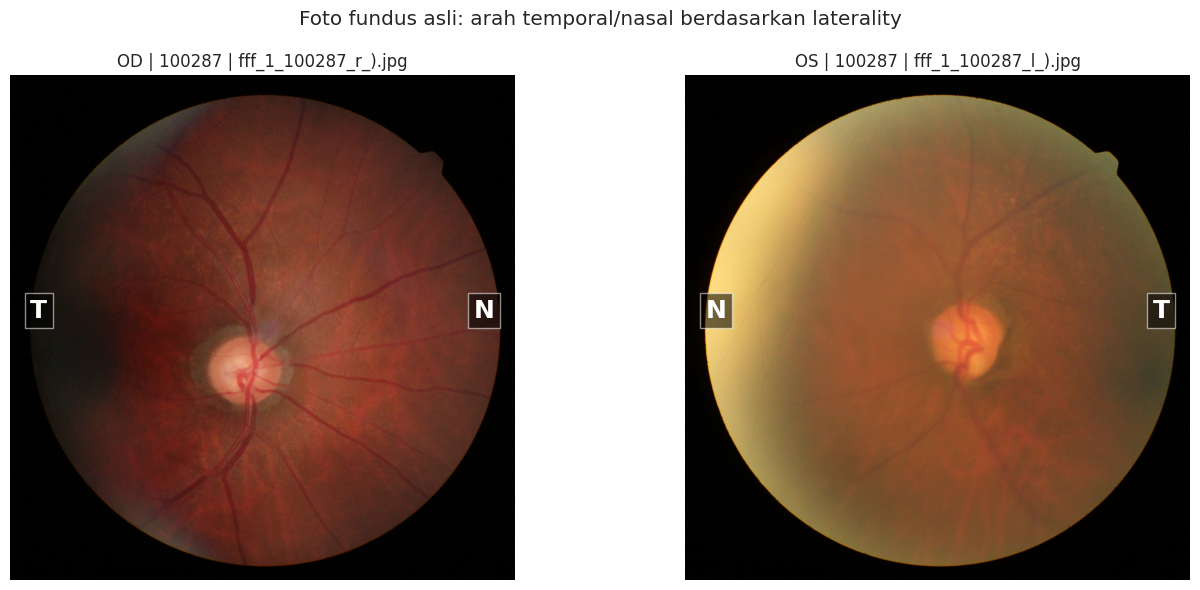

Belum ada pasangan OCT–fundus yang dapat ditampilkan. Tambahkan folder OCT ke Kaggle Input.


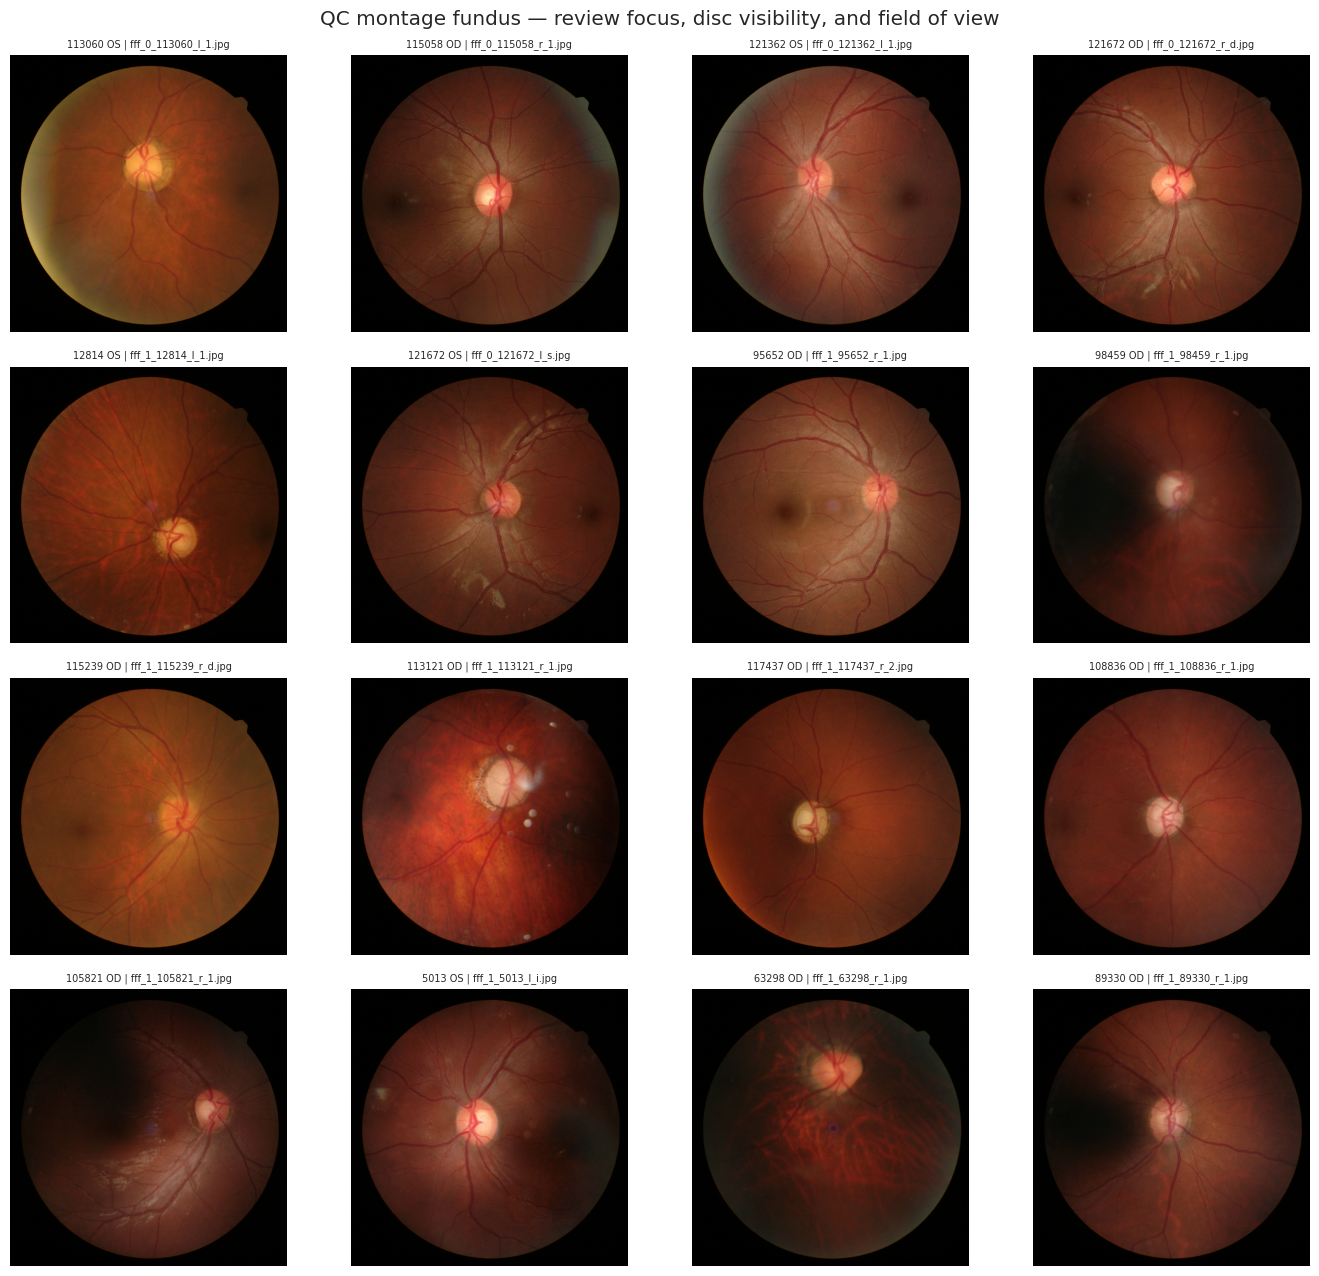

,selection_basis,candidate_count,n
0,first_sorted_candidate_selected_for_patient_eye,1,24
1,first_sorted_candidate_selected_for_patient_eye,2,19
2,first_sorted_candidate_selected_for_patient_eye,3,72
3,first_sorted_candidate_selected_for_patient_eye,4,3
4,reuse_patient_eye_selected_fundus,4,1
5,suffix_match_selected_for_patient_eye,1,25
6,suffix_match_selected_for_patient_eye,2,2
7,suffix_match_selected_for_patient_eye,3,6
8,suffix_match_selected_for_patient_eye,4,2
9,unmatched,0,21


PERHATIAN: pairing provisional belum diverifikasi memakai tanggal pengambilan foto/OCT.
Beberapa kandidat foto tidak menyebabkan baris RNFL dibuang; satu foto dipilih per pasien-mata dan dipakai konsisten.


In [4]:
# Show available OD/OS photos in their original orientation and mark temporal/nasal sides.
def load_rgb(path):
    with Image.open(path) as im:
        return im.convert("RGB").copy()

# Prefer two eyes from one patient when available, so the anatomical mirror is easy to inspect.
selected_examples = []
for pid, sub in df[df.fundus_path.notna()].groupby("patient_id"):
    by_eye = {eye: g.iloc[0] for eye, g in sub.groupby("laterality") if eye in {"OD","OS"}}
    if {"OD","OS"}.issubset(by_eye):
        selected_examples = [by_eye["OD"], by_eye["OS"]]
        break
if not selected_examples:
    for eye in ["OD","OS"]:
        hit = df[(df.laterality == eye) & df.fundus_path.notna()]
        if len(hit): selected_examples.append(hit.iloc[0])

if selected_examples:
    fig, axes = plt.subplots(1, len(selected_examples), figsize=(7*len(selected_examples), 6))
    if len(selected_examples) == 1: axes = [axes]
    for ax, row in zip(axes, selected_examples):
        im = load_rgb(row.fundus_path)
        ax.imshow(im); ax.axis("off")
        ax.set_title(f"{row.laterality} | {row.patient_id} | {Path(row.fundus_path).name}")
        if row.laterality == "OD":
            ax.text(.04,.52,"T",transform=ax.transAxes,color="white",fontsize=18,fontweight="bold",ha="left",bbox=dict(facecolor="black",alpha=.55))
            ax.text(.96,.52,"N",transform=ax.transAxes,color="white",fontsize=18,fontweight="bold",ha="right",bbox=dict(facecolor="black",alpha=.55))
        else:
            ax.text(.04,.52,"N",transform=ax.transAxes,color="white",fontsize=18,fontweight="bold",ha="left",bbox=dict(facecolor="black",alpha=.55))
            ax.text(.96,.52,"T",transform=ax.transAxes,color="white",fontsize=18,fontweight="bold",ha="right",bbox=dict(facecolor="black",alpha=.55))
    plt.suptitle("Foto fundus asli: arah temporal/nasal berdasarkan laterality")
    plt.tight_layout(); plt.show()

# Show a few exact patient-eye OCT report / fundus pairs when reports are supplied to Kaggle.
paired = df[df.fundus_path.notna() & df.oct_path.notna()].drop_duplicates(
    subset=["patient_id", "laterality", "oct_filename"])
if len(paired):
    sample_pairs = pd.concat([
        paired[paired.laterality == eye].head(1) for eye in ["OD", "OS"]
    ]).drop_duplicates().head(2)
    fig, axes = plt.subplots(len(sample_pairs), 2, figsize=(12, 5 * len(sample_pairs)))
    if len(sample_pairs) == 1: axes = np.asarray([axes])
    for row_axes, (_, row) in zip(axes, sample_pairs.iterrows()):
        row_axes[0].imshow(load_rgb(row.fundus_path)); row_axes[0].axis("off")
        row_axes[0].set_title(f"Fundus {row.patient_id} {row.laterality}\n{Path(row.fundus_path).name}")
        row_axes[1].imshow(load_rgb(row.oct_path)); row_axes[1].axis("off")
        row_axes[1].set_title(f"Laporan OCT {row.patient_id} {row.laterality}\n{Path(row.oct_path).name}")
    plt.suptitle("QC pasangan fundus–OCT; periksa ID, laterality, tanggal, dan T/N")
    plt.tight_layout(); plt.show()
else:
    print("Belum ada pasangan OCT–fundus yang dapat ditampilkan. Tambahkan folder OCT ke Kaggle Input.")

# Random fundus QC montage to inspect focus, field of view, and optic nerve visibility.
qc_pool = df[df.fundus_path.notna()].drop_duplicates(subset=["fundus_path"])
qc_sample = qc_pool.sample(n=min(16, len(qc_pool)), random_state=SEED)
fig, axes = plt.subplots(4,4,figsize=(14,13))
for ax in axes.flat:
    ax.axis("off")
for ax, (_, row) in zip(axes.flat, qc_sample.iterrows()):
    ax.imshow(load_rgb(row.fundus_path))
    ax.set_title(f"{row.patient_id} {row.laterality} | {Path(row.fundus_path).name}", fontsize=7)
    ax.axis("off")
plt.suptitle("QC montage fundus — review focus, disc visibility, and field of view")
plt.tight_layout(); plt.show()

display(pair_audit.groupby(["selection_basis","candidate_count"]).size().rename("n").reset_index())
print("PERHATIAN: pairing provisional belum diverifikasi memakai tanggal pengambilan foto/OCT.")
print("Beberapa kandidat foto tidak menyebabkan baris RNFL dibuang; satu foto dipilih per pasien-mata dan dipakai konsisten.")

## 5. Normalisasi jam RNFL dan pembentukan cohort

Di CSV, `rnfl_clock_0` berarti jam 1 sampai `rnfl_clock_11` berarti jam 12. Karena OCR membaca nilai di posisi diagram OCT, target OD dicerminkan untuk mengikuti konvensi Chen (jam 3 temporal, jam 9 nasal). Foto tetap utuh dan dalam orientasi aslinya. Target mentah dan target kanonis disimpan terpisah di memori untuk audit.

,raw_records,unique_patients_raw,missing_fundus_records,incomplete_12_label_records,excluded_union_records,analysis_records,analysis_patients,duplicate_patient_eye_records
0,175,90,21,2,23,152,84,1


Record analisis lengkap: 152
Pasien unik: 84
Sisi mata: {'OD': 78, 'OS': 74}
Diagnosis: {'glaucoma': 82, 'normal': 70}


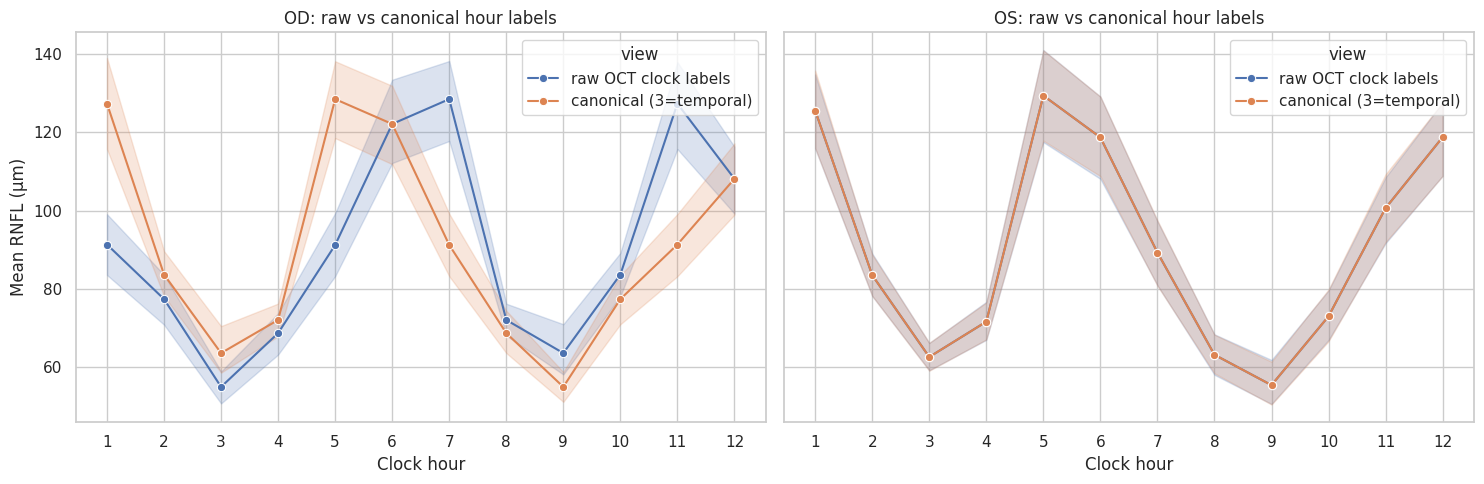

Baris yang memakai foto pilihan pasien-mata: 154
Pasien-mata dengan foto terpilih: 153
Nilai target kanonis (µm): 0.0 – 258.0


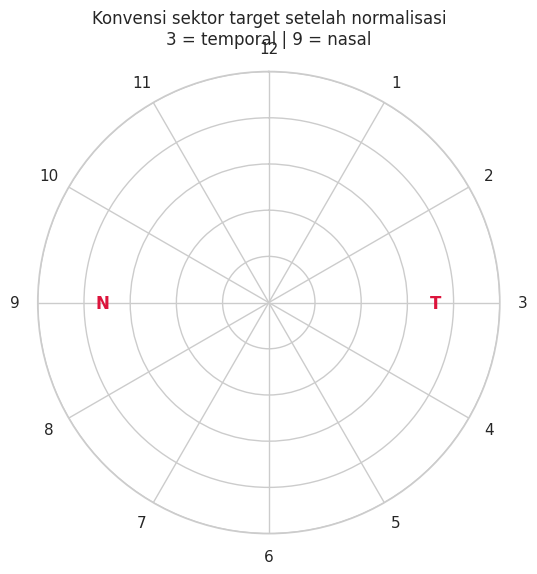

In [5]:
def reflect_clock_vector_od(values):
    # Jam h dipetakan ke (12-h) mod 12; pada indeks 0..11: i -> (10-i) mod 12.
    values = np.asarray(values, dtype=float)
    return values[np.array([(10-i) % 12 for i in range(12)])]

analysis = df[df.fundus_path.notna() & df[sector_cols].notna().all(axis=1)].copy().reset_index(drop=True)
Y_raw = analysis[sector_cols].to_numpy(dtype=np.float32)
Y = Y_raw.copy()
for i, eye in enumerate(analysis.laterality):
    if eye == "OD":
        Y[i] = reflect_clock_vector_od(Y_raw[i])
elif_bad = sorted(set(analysis.laterality) - {"OD","OS"})
if elif_bad:
    raise ValueError(f"Nilai laterality tak dikenal: {elif_bad}")
target_cols = [f"clock_{h}" for h in range(1,13)]
Y_df = pd.DataFrame(Y, columns=target_cols)
analysis[target_cols] = Y_df
analysis["fundus_path"] = analysis["fundus_path"].map(Path)

cohort_audit = pd.DataFrame([{
    "raw_records": len(df), "unique_patients_raw": df.patient_id.nunique(),
    "missing_fundus_records": int(df.fundus_path.isna().sum()),
    "incomplete_12_label_records": int((~df[sector_cols].notna().all(axis=1)).sum()),
    "excluded_union_records": int((~(df.fundus_path.notna() & df[sector_cols].notna().all(axis=1))).sum()),
    "analysis_records": len(analysis), "analysis_patients": analysis.patient_id.nunique(),
    "duplicate_patient_eye_records": int(df.duplicated(["patient_id","laterality"]).sum())
}])
cohort_audit.to_csv(OUTPUT_DIR / "ets_cohort_audit.csv", index=False)
display(cohort_audit)
print(f"Record analisis lengkap: {len(analysis)}")
print(f"Pasien unik: {analysis.patient_id.nunique()}")
print("Sisi mata:", analysis.laterality.value_counts().to_dict())
print("Diagnosis:", analysis.diagnosis.value_counts().to_dict())

# QC: compare clock-hour profiles before and after canonical right-eye normalization.
raw_profile = pd.DataFrame({"clock_hour": np.tile(np.arange(1,13), len(analysis)),
                            "RNFL_um": Y_raw.reshape(-1),
                            "laterality": np.repeat(analysis.laterality.to_numpy(), 12),
                            "view": "raw OCT clock labels"})
canon_profile = pd.DataFrame({"clock_hour": np.tile(np.arange(1,13), len(analysis)),
                              "RNFL_um": Y.reshape(-1),
                              "laterality": np.repeat(analysis.laterality.to_numpy(), 12),
                              "view": "canonical (3=temporal)"})
profile_qc = pd.concat([raw_profile, canon_profile], ignore_index=True)
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, eye in zip(axes, ["OD", "OS"]):
    sub = profile_qc[profile_qc.laterality == eye]
    sns.lineplot(data=sub, x="clock_hour", y="RNFL_um", hue="view", estimator="mean",
                 errorbar=("ci", 95), marker="o", ax=ax)
    ax.set_title(f"{eye}: raw vs canonical hour labels"); ax.set_xticks(range(1,13))
    ax.set_xlabel("Clock hour"); ax.set_ylabel("Mean RNFL (µm)")
plt.tight_layout(); plt.show()
print("Baris yang memakai foto pilihan pasien-mata:", int(pair_audit.selection_basis.isin(["reuse_patient_eye_selected_fundus", "first_sorted_candidate_selected_for_patient_eye", "suffix_match_selected_for_patient_eye", "manual_reviewed_patient_eye"]).sum()))
print("Pasien-mata dengan foto terpilih:", pair_audit.loc[pair_audit.selected_fundus_filename.ne(""), ["patient_id", "laterality"]].drop_duplicates().shape[0])
print("Nilai target kanonis (µm):", float(np.nanmin(Y)), "–", float(np.nanmax(Y)))

# Diagram posisi angka jam untuk orientasi analisis (3 temporal, 9 nasal)
theta = np.deg2rad(90 - (np.arange(1,13)-3)*30)
fig = plt.figure(figsize=(6,6)); ax = fig.add_subplot(111, projection="polar")
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
ax.set_xticks(np.deg2rad(np.arange(0,360,30)))
ax.set_xticklabels([str(h) for h in [12,1,2,3,4,5,6,7,8,9,10,11]])
ax.set_yticklabels([]); ax.set_title("Konvensi sektor target setelah normalisasi\n3 = temporal | 9 = nasal", pad=20)
for h in range(1,13):
    ang = np.deg2rad((h % 12)*30)
    ax.text(ang, 0.72, "T" if h==3 else ("N" if h==9 else ""), ha="center", va="center", color="crimson", fontweight="bold")
plt.show()


## 6. Split 5-fold GroupKFold berdasarkan pasien

Seluruh cohort dibagi menjadi lima fold. Setiap iterasi memakai satu fold validasi dan empat fold train; dua mata dari pasien yang sama tidak boleh terpisah. Manifest disimpan ke `rnfl_ets_outputs`.


Fold 1: train 121 mata/67 pasien; validasi 31 mata/17 pasien
Fold 2: train 121 mata/67 pasien; validasi 31 mata/17 pasien
Fold 3: train 122 mata/68 pasien; validasi 30 mata/16 pasien
Fold 4: train 122 mata/67 pasien; validasi 30 mata/17 pasien
Fold 5: train 122 mata/67 pasien; validasi 30 mata/17 pasien
5-fold patient GroupKFold: 152 mata, 84 pasien; overlap pasien antar train/val tidak ada.


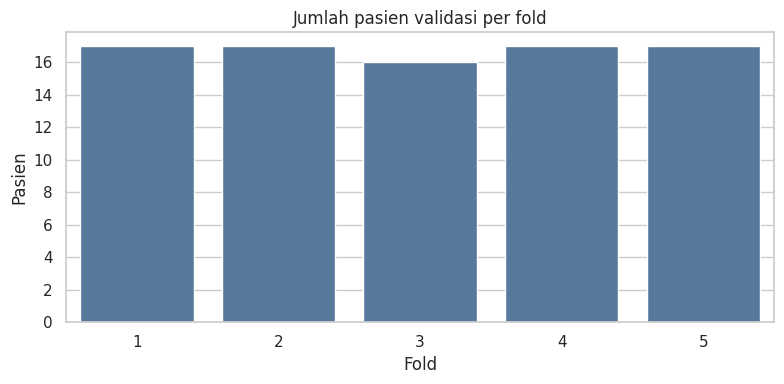

In [6]:
from sklearn.model_selection import GroupKFold

groups = analysis.patient_id.astype(str).to_numpy()
if np.unique(groups).size < N_FOLDS:
    raise ValueError(f"Perlu minimal {N_FOLDS} pasien berbeda untuk GroupKFold; tersedia {np.unique(groups).size}.")
outer_cv = GroupKFold(n_splits=N_FOLDS)
outer_splits = list(outer_cv.split(np.zeros(len(analysis)), groups=groups))
fold_rows = []
for fold_id, (tr, va) in enumerate(outer_splits, 1):
    trp, vap = set(groups[tr]), set(groups[va])
    assert trp.isdisjoint(vap)
    fold_rows.extend([{"fold": fold_id, "patient_id": groups[i], "sample_index": int(i), "split": split}
                      for split, arr in [("train", tr), ("val", va)] for i in arr])
    print(f"Fold {fold_id}: train {len(tr)} mata/{len(trp)} pasien; validasi {len(va)} mata/{len(vap)} pasien")
fold_manifest = pd.DataFrame(fold_rows)
fold_manifest.to_csv(OUTPUT_DIR / "patient_groupkfold_manifest.csv", index=False)
fold_manifest.groupby(["fold", "split"]).agg(eyes=("patient_id", "size"), patients=("patient_id", "nunique")).to_csv(OUTPUT_DIR / "split_counts.csv")
print(f"5-fold patient GroupKFold: {len(analysis)} mata, {len(np.unique(groups))} pasien; overlap pasien antar train/val tidak ada.")

fig, ax = plt.subplots(figsize=(8,4))
fold_counts = fold_manifest[fold_manifest.split == "val"].groupby("fold").patient_id.nunique()
sns.barplot(x=fold_counts.index.astype(str), y=fold_counts.values, ax=ax, color="#4C78A8")
ax.set_title("Jumlah pasien validasi per fold"); ax.set_xlabel("Fold"); ax.set_ylabel("Pasien")
plt.tight_layout(); plt.show()

## 7. Muat RETFound CFP bila tersedia

Jika `models_vit.py`, folder `util/`, checkpoint CFP, serta PyTorch tersedia, model RETFound ViT-Large dibekukan dan dipakai sebagai ekstraktor fitur. Jika tidak, sel berikut memakai fitur gambar sederhana dan seluruh pipeline ETS tetap berjalan. Sumber fitur selalu dicatat dalam output.

Paper Chen menyebut latent vector 128 dimensi tanpa menjelaskan proyeksinya; embedding pooled ViT-Large dapat berdimensi 1024. Perbedaan ini harus disebut sebagai batas replikasi. Tidak ada proyeksi PCA untuk pelatihan model.


In [7]:
RETFOUND_READY = False
if torch is None or not MODEL_CODE_HITS or not WEIGHT_HITS:
    print("RETFound CFP belum tersedia; memakai fitur gambar sederhana untuk seluruh eksperimen ETS.")
else:
    try:
        if not torch.cuda.is_available():
            print("GPU tidak aktif; ekstraksi fitur ViT-Large akan lambat. Aktifkan GPU T4/P100 di Kaggle.")
        DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        print("Device:", DEVICE)

        repo_root = MODEL_CODE_HITS[0].parent
        sys.path.insert(0, str(repo_root))
        try:
            import models_vit
        except Exception as e:
            raise ImportError(f"Gagal import models_vit.py dari {repo_root}: {e}")

        if hasattr(models_vit, "RETFound_mae"):
            # Current official RETFound repository factory (ViT-L/16 CFP).
            model = models_vit.RETFound_mae(img_size=224, num_classes=5, drop_path_rate=0, global_pool=True)
        elif hasattr(models_vit, "vit_large_patch16"):
            # Older official repository factory.
            model = models_vit.vit_large_patch16(img_size=224, num_classes=2, drop_path_rate=0.2, global_pool=True)
        else:
            raise AttributeError("models_vit.py tidak memiliki factory RETFound_mae atau vit_large_patch16.")

        ckpt_path = WEIGHT_HITS[0]
        checkpoint = torch.load(ckpt_path, map_location="cpu", weights_only=False)
        state = checkpoint.get("model", checkpoint.get("state_dict", checkpoint))
        state = {k.removeprefix("module."): v for k,v in state.items()}
        # Discard an incompatible classification head; keep the pretrained ViT trunk.
        for key in ["head.weight","head.bias"]:
            if key in state and key in model.state_dict() and state[key].shape != model.state_dict()[key].shape:
                del state[key]
        try:
            from util.pos_embed import interpolate_pos_embed
            interpolate_pos_embed(model, state)
        except Exception as e:
            print("Interpolasi positional embedding dilewati:", repr(e))
        msg = model.load_state_dict(state, strict=False)
        print("Checkpoint:", ckpt_path, "| missing:", len(msg.missing_keys), "| unexpected:", len(msg.unexpected_keys))
        print("Missing key examples:", msg.missing_keys[:12])
        print("Unexpected key examples:", msg.unexpected_keys[:12])
        model.head = nn.Identity()
        model.eval().to(DEVICE)
        for p in model.parameters():
            p.requires_grad_(False)
        print("RETFound pooled feature size:", model.embed_dim if hasattr(model,"embed_dim") else "akan dicek saat forward")
        RETFOUND_READY = True
    except Exception as exc:
        RETFOUND_READY = False
        print("RETFound gagal dimuat; beralih ke fitur gambar sederhana:", repr(exc))


Device: cuda


/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


Checkpoint: /kaggle/input/datasets/septiadiniarifta/retfound/RETFound_official/RETFound_mae_natureCFP.pth | missing: 4 | unexpected: 106
Missing key examples: ['fc_norm.weight', 'fc_norm.bias', 'head.weight', 'head.bias']
Unexpected key examples: ['mask_token', 'decoder_pos_embed', 'norm.weight', 'norm.bias', 'decoder_embed.weight', 'decoder_embed.bias', 'decoder_blocks.0.norm1.weight', 'decoder_blocks.0.norm1.bias', 'decoder_blocks.0.attn.qkv.weight', 'decoder_blocks.0.attn.qkv.bias', 'decoder_blocks.0.attn.proj.weight', 'decoder_blocks.0.attn.proj.bias']
RETFound pooled feature size: 1024


## 8. Dua view citra dan ekstraksi fitur

View asli digunakan untuk pelatihan dasar dan seluruh evaluasi. View kedua dibuat dengan perubahan brightness, contrast, dan saturation ±10% yang deterministik; hanya baris train fold yang masuk ke model augmentasi. RETFound menggunakan resize/center crop 224×224 dan normalisasi ImageNet. Mode fitur sederhana menggunakan thumbnail abu-abu, histogram RGB, dan statistik warna. Kedua mode mempertahankan orientasi foto.

RETFound resmi mengembalikan fitur yang sudah dipool dari `forward_features()`; notebook mengambil vektor tersebut langsung tanpa `forward_head()` kedua.


Sumber fitur: RETFound CFP frozen | Matriks asli/augmentasi: (152, 1024)
Augmentasi: brightness, contrast, saturation ±10%; tanpa flip atau perubahan target.


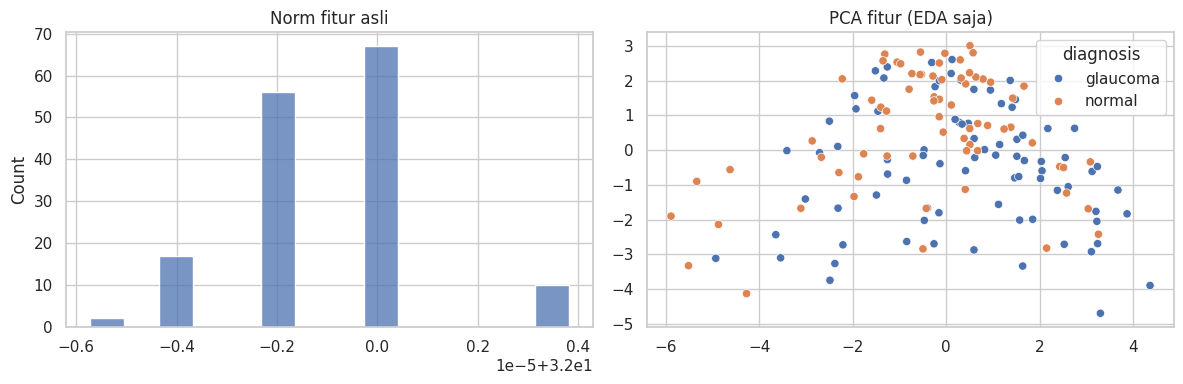

In [8]:
# Ekstrak dua view tiap foto: asli untuk semua evaluasi, fotometrik untuk train saja.
# Fitur sederhana memungkinkan Run All tanpa unduhan bobot 3,95 GB.
FEATURE_SOURCE = "RETFound CFP frozen" if RETFOUND_READY else "handcrafted image baseline"
FEATURE_READY = True

def photometric_view(im, seed):
    rng = np.random.default_rng(seed)
    im = ImageEnhance.Brightness(im).enhance(float(rng.uniform(.90, 1.10)))
    im = ImageEnhance.Contrast(im).enhance(float(rng.uniform(.90, 1.10)))
    im = ImageEnhance.Color(im).enhance(float(rng.uniform(.90, 1.10)))
    return im

def simple_features(im):
    rgb = np.asarray(im.resize((32, 32), Image.Resampling.BICUBIC), dtype=np.float32) / 255.0
    gray = np.asarray(ImageOps.grayscale(im).resize((16, 16), Image.Resampling.BICUBIC), dtype=np.float32).ravel() / 255.0
    hist = np.concatenate([np.histogram(rgb[:, :, c], bins=16, range=(0, 1), density=False)[0] / 1024 for c in range(3)])
    stats = np.r_[rgb.mean(axis=(0,1)), rgb.std(axis=(0,1))]
    return np.r_[gray, hist, stats].astype(np.float32)

if RETFOUND_READY:
    preprocess = transforms.Compose([
        transforms.Resize(IMAGE_SIZE, interpolation=InterpolationMode.BICUBIC),
        transforms.CenterCrop(IMAGE_SIZE), transforms.ToTensor(),
        transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])])
    class FundusDataset(Dataset):
        def __init__(self, frame, augmented=False):
            self.frame = frame.reset_index(drop=True); self.augmented = augmented
        def __len__(self): return len(self.frame)
        def __getitem__(self, i):
            with Image.open(self.frame.iloc[i].fundus_path) as im:
                im = im.convert("RGB")
                if self.augmented: im = photometric_view(im, SEED + i)
                return preprocess(im), i
    def encode_dataset(augmented=False):
        loader = DataLoader(FundusDataset(analysis, augmented), batch_size=BATCH_SIZE,
                            shuffle=False, num_workers=NUM_WORKERS, pin_memory=(DEVICE.type=="cuda"))
        batches = []
        with torch.inference_mode():
            for xb, _ in loader:
                xb = xb.to(DEVICE, non_blocking=True)
                if DEVICE.type == "cuda":
                    with torch.autocast(device_type="cuda", dtype=torch.float16): raw = model.forward_features(xb)
                else: raw = model.forward_features(xb)
                if isinstance(raw, (tuple, list)): raw = raw[0]
                # RETFound official sudah melakukan average pooling + fc_norm di
                # forward_features dan menghasilkan [batch, 1, 1024]. Memanggil
                # timm.forward_head lagi akan gagal karena global_pool model ini bool.
                if raw.ndim == 3 and raw.shape[1] == 1:
                    feat = raw[:, 0, :]
                elif raw.ndim == 3 and isinstance(getattr(model, "global_pool", None), bool):
                    feat = (model.fc_norm(raw[:, 1:, :].mean(dim=1))
                            if model.global_pool else raw[:, 0, :])
                elif raw.ndim == 3 and hasattr(model, "forward_head"):
                    feat = model.forward_head(raw, pre_logits=True)
                elif raw.ndim == 3:
                    feat = raw[:, 0, :]
                else:
                    feat = raw
                if feat.ndim != 2:
                    raise ValueError(f"Fitur RETFound harus [batch, dimensi], diperoleh {tuple(feat.shape)}")
                batches.append(feat.float().cpu().numpy())
        return np.concatenate(batches).astype(np.float32)
    X = encode_dataset(False)
    X_aug = encode_dataset(True)
else:
    original, augmented = [], []
    for i, path in enumerate(analysis.fundus_path):
        with Image.open(path) as image:
            im = image.convert("RGB")
            original.append(simple_features(im))
            augmented.append(simple_features(photometric_view(im, SEED + i)))
    X = np.stack(original); X_aug = np.stack(augmented)
assert X.ndim == 2 and X_aug.ndim == 2, f"Dimensi fitur salah: {X.shape}, {X_aug.shape}"
assert X.shape == X_aug.shape and X.shape[0] == len(analysis)
assert np.isfinite(X).all() and np.isfinite(X_aug).all()
np.save(OUTPUT_DIR / "features_original.npy", X)
np.save(OUTPUT_DIR / "features_augmented_photometric.npy", X_aug)
(OUTPUT_DIR / "feature_source.txt").write_text(FEATURE_SOURCE + "\n")
print("Sumber fitur:", FEATURE_SOURCE, "| Matriks asli/augmentasi:", X.shape)
print("Augmentasi: brightness, contrast, saturation ±10%; tanpa flip atau perubahan target.")
from sklearn.decomposition import PCA
if len(X) >= 2:
    X2 = PCA(n_components=2, random_state=SEED).fit_transform(X)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(np.linalg.norm(X, axis=1), ax=ax[0]); ax[0].set_title("Norm fitur asli")
    sns.scatterplot(x=X2[:,0], y=X2[:,1], hue=analysis.diagnosis, ax=ax[1]); ax[1].set_title("PCA fitur (EDA saja)")
    plt.tight_layout(); plt.show()

## 9. Evaluasi luar 5-fold dan tuning internal

Empat regresor Chen diuji dengan prediksi OOF pada fold validasi. Hyperparameter dituning memakai 3-fold GroupKFold internal pada train fold, sehingga fold validasi luar tidak ikut menentukan parameter. StandardScaler di-fit hanya pada data train.


In [9]:
if FEATURE_READY:
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
    from sklearn.model_selection import GridSearchCV, GroupKFold
    from sklearn.multioutput import MultiOutputRegressor
    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

    Y_all = analysis[target_cols].to_numpy(dtype=np.float32)
    X_all = X
    model_specs = {
        "OLS": (LinearRegression(), {}),
        "Ridge": (Ridge(), {"regressor__alpha":[0.1,10,1000]}),
        "Lasso": (MultiOutputRegressor(Lasso(max_iter=5000, tol=0.001)), {"regressor__estimator__alpha":[0.01,0.1,1]}),
        "ElasticNet": (MultiOutputRegressor(ElasticNet(max_iter=5000, tol=0.001)), {
            "regressor__estimator__alpha":[0.01,0.1,1],
            "regressor__estimator__l1_ratio":[0.1,0.9]})
    }
    def make_pipe(reg): return Pipeline([("scale", StandardScaler()), ("regressor", reg)])
    def regression_metrics(y_true, y_pred):
        return {"MAE_um":mean_absolute_error(y_true.reshape(-1), y_pred.reshape(-1)),
                "MSE_um2":mean_squared_error(y_true.reshape(-1), y_pred.reshape(-1)),
                "RMSE_um":mean_squared_error(y_true.reshape(-1), y_pred.reshape(-1))**0.5,
                "R2":r2_score(y_true.reshape(-1), y_pred.reshape(-1))}

    oof_predictions = {name: np.full_like(Y_all, np.nan, dtype=np.float64) for name in model_specs}
    cv_summaries, cv_tables, fold_rows = [], [], []
    for fold_id, (tr, va) in enumerate(outer_splits, 1):
        inner_cv = GroupKFold(n_splits=min(3, len(np.unique(groups[tr]))))
        inner_splits = list(inner_cv.split(X_all[tr], Y_all[tr], groups=groups[tr]))
        assert all(set(groups[tr][a]).isdisjoint(set(groups[tr][b])) for a,b in inner_splits)
        for name, (regressor, grid) in model_specs.items():
            if grid:
                search = GridSearchCV(make_pipe(regressor), grid, scoring="neg_mean_squared_error",
                                      cv=inner_splits, refit=True, n_jobs=2, return_train_score=True)
                search.fit(X_all[tr], Y_all[tr])
                fitted, params, inner_mse = search.best_estimator_, search.best_params_, -float(search.best_score_)
                tab = pd.DataFrame(search.cv_results_); tab["model"] = name; tab["outer_fold"] = fold_id; cv_tables.append(tab)
            else:
                fold_mse=[]
                for a,b in inner_splits:
                    pipe=make_pipe(LinearRegression()); pipe.fit(X_all[tr][a],Y_all[tr][a])
                    fold_mse.append(mean_squared_error(Y_all[tr][b],pipe.predict(X_all[tr][b])))
                inner_mse=float(np.mean(fold_mse)); params={}
                fitted=make_pipe(LinearRegression()).fit(X_all[tr],Y_all[tr])
            pred=fitted.predict(X_all[va]); oof_predictions[name][va]=pred
            cv_summaries.append({"outer_fold":fold_id,"model":name,"inner_cv_mse":inner_mse,"best_params":str(params)})
            fold_rows.append({"fold":fold_id,"model":name,**regression_metrics(Y_all[va],pred)})
            print(f"Fold {fold_id} | {name} | inner CV MSE {inner_mse:.3f} | OOF MAE {mean_absolute_error(Y_all[va].ravel(),pred.ravel()):.2f} µm")

    cv_summary = pd.DataFrame(cv_summaries); fold_results = pd.DataFrame(fold_rows)
    cv_summary["feature_source"] = FEATURE_SOURCE; fold_results["feature_source"] = FEATURE_SOURCE
    cv_summary.to_csv(OUTPUT_DIR / "ets_groupkfold_tuning_by_fold.csv", index=False)
    fold_results.to_csv(OUTPUT_DIR / "fold_validation_metrics.csv", index=False)
    if cv_tables: pd.concat(cv_tables,ignore_index=True).to_csv(OUTPUT_DIR / "ets_groupkfold_gridsearch_all.csv",index=False)

    overall_rows=[]; sector_rows=[]; pred_rows=[]
    for name,pred in oof_predictions.items():
        overall_rows.append({"model":name,**regression_metrics(Y_all,pred)})
        for j in range(12):
            sector_rows.append({"model":name,"clock_hour":j+1,
                "MAE_um":mean_absolute_error(Y_all[:,j],pred[:,j]),
                "RMSE_um":mean_squared_error(Y_all[:,j],pred[:,j])**0.5,
                "R2":r2_score(Y_all[:,j],pred[:,j]) if np.std(Y_all[:,j])>0 else np.nan,
                "Pearson_r":np.corrcoef(Y_all[:,j],pred[:,j])[0,1] if np.std(Y_all[:,j])>0 and np.std(pred[:,j])>0 else np.nan})
        for i,row in analysis.iterrows():
            rec={"model":name,"patient_id":row.patient_id,"laterality":row.laterality,"sample_index":i}
            for j,col in enumerate(target_cols): rec[f"{col}_actual_um"]=float(Y_all[i,j]); rec[f"{col}_pred_um"]=float(pred[i,j])
            pred_rows.append(rec)
    overall_results=pd.DataFrame(overall_rows).sort_values("MAE_um")
    sector_results=pd.DataFrame(sector_rows); oof_pred_df=pd.DataFrame(pred_rows)
    overall_results["feature_source"] = FEATURE_SOURCE
    sector_results["feature_source"] = FEATURE_SOURCE; oof_pred_df["feature_source"] = FEATURE_SOURCE
    display(overall_results); display(fold_results)
    overall_results.to_csv(OUTPUT_DIR/"ets_oof_overall_metrics.csv",index=False)
    sector_results.to_csv(OUTPUT_DIR/"ets_oof_metrics_by_clock_hour.csv",index=False)
    oof_pred_df.to_csv(OUTPUT_DIR/"ets_oof_predictions.csv",index=False)
    mean_inner=cv_summary.groupby("model").inner_cv_mse.mean().sort_values()
    best_name=mean_inner.index[0]
    best_pred=oof_predictions[best_name]
    print("Regresor terpilih berdasarkan rerata inner-CV MSE:",best_name)
else:
    print("Dilewati: fitur tidak tersedia; jalankan ulang setelah menambahkan checkpoint dan source code.")

Fold 1 | OLS | inner CV MSE 1114.974 | OOF MAE 23.80 µm
Fold 1 | Ridge | inner CV MSE 839.240 | OOF MAE 20.26 µm
Fold 1 | Lasso | inner CV MSE 1028.422 | OOF MAE 20.89 µm


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.479e+01, tolerance: 2.176e+01
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.538e+01, tolerance: 3.079e+01
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.849e+02, tolerance: 1.722e

Fold 1 | ElasticNet | inner CV MSE 941.886 | OOF MAE 20.43 µm
Fold 2 | OLS | inner CV MSE 1055.119 | OOF MAE 24.02 µm
Fold 2 | Ridge | inner CV MSE 804.379 | OOF MAE 20.97 µm
Fold 2 | Lasso | inner CV MSE 981.385 | OOF MAE 21.83 µm


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.175e+01, tolerance: 3.199e+01
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.266e+02, tolerance: 1.239e+02
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.546e+01, tolerance: 4.091e

Fold 2 | ElasticNet | inner CV MSE 873.640 | OOF MAE 21.85 µm
Fold 3 | OLS | inner CV MSE 1026.924 | OOF MAE 25.54 µm
Fold 3 | Ridge | inner CV MSE 765.002 | OOF MAE 22.58 µm
Fold 3 | Lasso | inner CV MSE 914.880 | OOF MAE 23.54 µm


...

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.039e+01, tolerance: 3.150e+01
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.016e+01, tolerance: 2.893e+01
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.770e+01, tolerance: 4.726e

Fold 5 | ElasticNet | inner CV MSE 891.854 | OOF MAE 20.85 µm


,model,MAE_um,MSE_um2,RMSE_um,R2,feature_source
1,Ridge,20.628771,749.698011,27.380614,0.591709,RETFound CFP frozen
3,ElasticNet,21.464231,808.633884,28.436489,0.559612,RETFound CFP frozen
2,Lasso,22.053619,854.649348,29.234386,0.534551,RETFound CFP frozen
0,OLS,24.684590,1065.686098,32.644848,0.419619,RETFound CFP frozen


,fold,model,MAE_um,MSE_um2,RMSE_um,R2,feature_source
0,1,OLS,23.802094,949.102844,30.807513,0.530133,RETFound CFP frozen
1,1,Ridge,20.260574,674.246948,25.966266,0.666204,RETFound CFP frozen
2,1,Lasso,20.886438,735.774475,27.125163,0.635744,RETFound CFP frozen
3,1,ElasticNet,20.433342,681.313660,26.101986,0.662706,RETFound CFP frozen
4,2,OLS,24.023979,1061.208374,32.576193,0.421555,RETFound CFP frozen
5,2,Ridge,20.965778,817.220581,28.587070,0.554548,RETFound CFP frozen
6,2,Lasso,21.831495,868.443115,29.469359,0.526627,RETFound CFP frozen
7,2,ElasticNet,21.845629,878.990234,29.647769,0.520878,RETFound CFP frozen
8,3,OLS,25.541023,1156.003418,34.000050,0.434400,RETFound CFP frozen
9,3,Ridge,22.576647,938.080200,30.628095,0.541023,RETFound CFP frozen


Regresor terpilih berdasarkan rerata inner-CV MSE: Ridge


## 9A. Augmentasi, ensemble, dan pembanding model

Augmentasi dibuat dari foto asli dengan perubahan fotometrik ±10% dan label yang sama. Pada tiap fold, **hanya** dua view milik pasien train dipakai untuk fit model. Fold validasi selalu memakai view asli dan hanya satu prediksi per mata. Tidak ada augmentasi horizontal karena orientasi OD/OS dan jam RNFL bermakna anatomi.

Ensemble memakai rata-rata prediksi Ridge dan ExtraTrees (bobot 0,5/0,5 yang ditetapkan sebelum melihat fold validasi). Bandingkan Ridge, ExtraTrees, ensemble tanpa augmentasi, dan ensemble dengan augmentasi menggunakan fold dan metrik yang identik. Hasil tiap fold dan gabungan OOF tersimpan sebagai CSV. Kenaikan performa **tidak diasumsikan**; periksa metrik dan interval ketidakpastian.

Fold 1: pasien train/val 67/17; augmentasi train 242 view
Fold 2: pasien train/val 67/17; augmentasi train 242 view
Fold 3: pasien train/val 68/16; augmentasi train 244 view
Fold 4: pasien train/val 67/17; augmentasi train 244 view
Fold 5: pasien train/val 67/17; augmentasi train 244 view


,model,feature_source,MAE_um,MSE_um2,RMSE_um,R2
3,Ensemble + augmentasi,RETFound CFP frozen,20.533838,741.604761,27.232421,0.596116
0,Ridge,RETFound CFP frozen,20.628822,749.703176,27.380708,0.591706
2,Ensemble,RETFound CFP frozen,20.702635,753.100391,27.442675,0.589856
1,ExtraTrees,RETFound CFP frozen,21.355546,797.868924,28.246574,0.565474


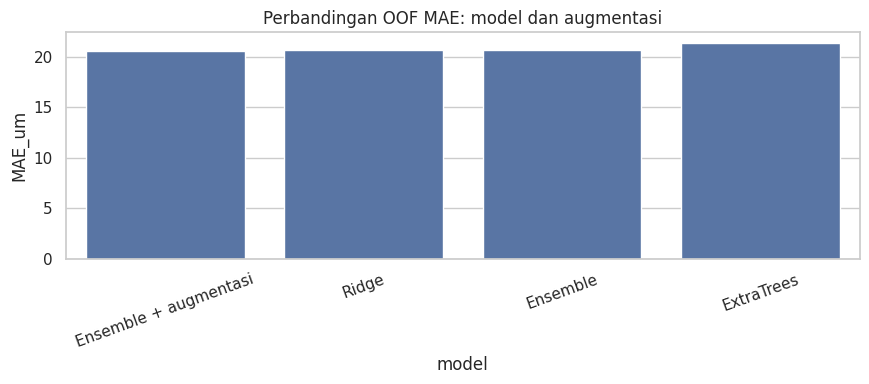

Selisih MAE Ridge - Ensemble+augmentasi (positif = perbaikan), 95% CI pasien: [-0.23242294  0.08659746  0.397939  ]


In [10]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

Y_all = analysis[target_cols].to_numpy(dtype=np.float32)
ensemble_names = ["Ridge", "ExtraTrees", "Ensemble", "Ensemble + augmentasi"]
ensemble_oof = {name: np.full_like(Y_all, np.nan, dtype=np.float64) for name in ensemble_names}
ensemble_fold_rows = []

def make_ridge(alpha): return make_pipeline(StandardScaler(), Ridge(alpha=alpha, solver="lsqr"))
def make_trees():
    return ExtraTreesRegressor(n_estimators=160, min_samples_leaf=2,
                               max_features=.8, random_state=SEED, n_jobs=-1)

for fold_id, (tr, va) in enumerate(outer_splits, 1):
    tuned = cv_summary.query("outer_fold == @fold_id and model == 'Ridge'").iloc[0]
    import ast
    alpha = float(ast.literal_eval(tuned.best_params).get("regressor__alpha", 1.0))
    ridge = make_ridge(alpha).fit(X[tr], Y_all[tr])
    trees = make_trees().fit(X[tr], Y_all[tr])
    X_train_aug = np.concatenate([X[tr], X_aug[tr]], axis=0)
    Y_train_aug = np.concatenate([Y_all[tr], Y_all[tr]], axis=0)
    ridge_aug = make_ridge(alpha).fit(X_train_aug, Y_train_aug)
    trees_aug = make_trees().fit(X_train_aug, Y_train_aug)
    pr, pt = ridge.predict(X[va]), trees.predict(X[va])
    pa = (ridge_aug.predict(X[va]) + trees_aug.predict(X[va])) / 2
    fold_pred = {"Ridge": pr, "ExtraTrees": pt,
                 "Ensemble": (pr + pt) / 2, "Ensemble + augmentasi": pa}
    for name, pred in fold_pred.items():
        ensemble_oof[name][va] = pred
        ensemble_fold_rows.append({"fold":fold_id, "model":name, "feature_source":FEATURE_SOURCE,
                                   **regression_metrics(Y_all[va], pred)})
    print(f"Fold {fold_id}: pasien train/val {len(np.unique(groups[tr]))}/{len(np.unique(groups[va]))}; augmentasi train {len(X_train_aug)} view")
assert all(np.isfinite(v).all() for v in ensemble_oof.values())
ensemble_fold = pd.DataFrame(ensemble_fold_rows)
ensemble_overall = pd.DataFrame([{"model":n, "feature_source":FEATURE_SOURCE,
                                  **regression_metrics(Y_all, p)} for n,p in ensemble_oof.items()]).sort_values("MAE_um")
ensemble_fold.to_csv(OUTPUT_DIR/"ets_ensemble_fold_metrics.csv", index=False)
ensemble_overall.to_csv(OUTPUT_DIR/"ets_ensemble_oof_metrics.csv", index=False)
pd.DataFrame({"patient_id":groups, "laterality":analysis.laterality, "sample_index":np.arange(len(analysis)),
              **{f"{name}_clock_{j+1}":p[:,j] for name,p in ensemble_oof.items() for j in range(12)}}).to_csv(
                  OUTPUT_DIR/"ets_ensemble_oof_predictions.csv", index=False)
display(ensemble_overall)
fig, ax = plt.subplots(figsize=(9,4))
sns.barplot(data=ensemble_overall, x="model", y="MAE_um", ax=ax)
ax.set_title("Perbandingan OOF MAE: model dan augmentasi"); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()
# CI selisih berpasangan dengan resampling pasien, bukan mata.
rng = np.random.default_rng(SEED)
patient_ids = np.unique(groups)
differences = []
for _ in range(1000):
    chosen = rng.choice(patient_ids, size=len(patient_ids), replace=True)
    ii = np.concatenate([np.flatnonzero(groups == pid) for pid in chosen])
    mae_base = mean_absolute_error(Y_all[ii].ravel(), ensemble_oof["Ridge"][ii].ravel())
    mae_aug = mean_absolute_error(Y_all[ii].ravel(), ensemble_oof["Ensemble + augmentasi"][ii].ravel())
    differences.append(mae_base-mae_aug)
ci = np.quantile(differences, [.025,.5,.975])
print("Selisih MAE Ridge - Ensemble+augmentasi (positif = perbaikan), 95% CI pasien:", ci)
pd.DataFrame({"bootstrap_mae_improvement_um":differences}).to_csv(OUTPUT_DIR/"ets_ensemble_paired_bootstrap.csv", index=False)

## 9B. Reinforcement learning: bandit UCB1 untuk memilih data berlabel

Simulasi dilakukan **di dalam train fold**. Sebagian pasien train menjadi validasi reward yang tetap dan tidak ikut dilabeli. Dari sisa pasien, kebijakan dimulai dengan 30% pasien berlabel lalu memilih batch baru selama lima putaran. Aksi bandit adalah `uncertainty` (perbedaan prediksi tiga Ridge), `diversity` (jarak fitur ke data berlabel), atau `random`. Reward = penurunan MAE pada validasi reward setelah batch ditambahkan. UCB1 memperbarui nilai aksi dari reward yang sudah diamati. Ini adalah *multi-armed bandit*, bentuk sederhana reinforcement learning; tidak memakai state klinis atau agen diagnosis.

Kebijakan acak dengan pasien awal dan anggaran label yang sama menjadi pembanding. MAE pada fold luar dihitung hanya untuk **pelaporan kurva belajar** dan tidak memengaruhi pemilihan aksi. Performa dapat naik atau turun ketika data ditambahkan; hasil aktual dan keterbatasannya dibahas di akhir.

,policy,round,mean_labeled_patients,mean_outer_MAE_um,sd_outer_MAE_um,mean_reward_MAE_um
0,UCB1,0,16.2,26.200403,1.194408,26.823146
1,UCB1,1,22.2,24.981238,1.648040,25.306478
2,UCB1,2,28.2,24.766616,1.603796,24.636984
3,UCB1,3,34.2,24.204111,1.691498,24.622099
4,UCB1,4,40.2,24.286267,1.559917,24.842355
5,UCB1,5,46.2,24.095493,1.481345,24.603822
6,random,0,16.2,26.200403,1.194408,26.823146
7,random,1,22.2,25.613145,0.899342,25.915408
8,random,2,28.2,25.105530,0.953212,26.050315
9,random,3,34.2,24.526787,1.352116,25.289884


Frekuensi aksi UCB1: {'uncertainty': 11, 'diversity': 8, 'random': 6}


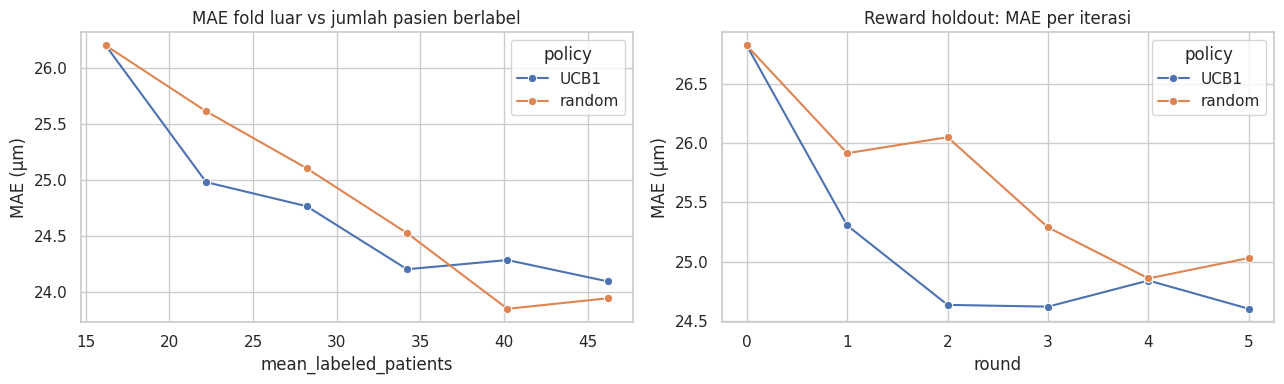

In [11]:
from sklearn.model_selection import GroupShuffleSplit

RL_ROUNDS = 5
RL_STRATEGIES = ("uncertainty", "diversity", "random")
rl_records = []

def patient_indices(ids, g): return np.flatnonzero(np.isin(g, list(ids)))
def score_candidates(strategy, selected, available, X_train, g_train, fitted, rng):
    if strategy == "random": return {pid:float(rng.random()) for pid in available}
    selected_idx = patient_indices(selected, g_train)
    available_idx = patient_indices(available, g_train)
    if strategy == "diversity":
        scaled = fitted.named_steps["standardscaler"].transform(X_train)
        from sklearn.metrics import pairwise_distances
        dist = pairwise_distances(scaled[available_idx], scaled[selected_idx]).min(axis=1)
        sample_score = dict(zip(available_idx, dist))
    else:
        alternatives = [make_ridge(a).fit(X_train[selected_idx], Y_train[selected_idx]) for a in (.1,10,100)]
        pp = np.stack([m.predict(X_train[available_idx]) for m in alternatives])
        uncertainty = pp.std(axis=0).mean(axis=1)
        sample_score = dict(zip(available_idx, uncertainty))
    return {pid:float(np.mean([sample_score[i] for i in np.flatnonzero(g_train==pid)])) for pid in available}

for fold_id,(tr,va) in enumerate(outer_splits,1):
    X_train, Y_train, g_train = X[tr], Y_all[tr], groups[tr]
    split = GroupShuffleSplit(n_splits=1, test_size=.20, random_state=SEED+fold_id)
    pool_idx, reward_idx = next(split.split(X_train, Y_train, groups=g_train))
    pool_patients = np.unique(g_train[pool_idx])
    rng_seed = np.random.default_rng(SEED+fold_id)
    initial_n = max(2, int(np.ceil(.30*len(pool_patients))))
    initial = set(rng_seed.choice(pool_patients, size=initial_n, replace=False))
    batch_n = max(1, int(np.ceil(.10*len(pool_patients))))
    assert set(g_train[reward_idx]).isdisjoint(set(pool_patients))
    for policy in ("UCB1", "random"):
        rng = np.random.default_rng(SEED+1000*fold_id)
        selected = set(initial)
        counts = {s:0 for s in RL_STRATEGIES}; total_rewards = {s:0.0 for s in RL_STRATEGIES}
        prev_reward_mae = None
        for round_id in range(RL_ROUNDS+1):
            chosen_idx = patient_indices(selected, g_train)
            fitted = make_ridge(10.0).fit(X_train[chosen_idx],Y_train[chosen_idx])
            reward_mae = mean_absolute_error(Y_train[reward_idx].ravel(), fitted.predict(X_train[reward_idx]).ravel())
            outer_mae = mean_absolute_error(Y_all[va].ravel(), fitted.predict(X[va]).ravel())
            rl_records.append({"fold":fold_id,"policy":policy,"round":round_id,
                               "labeled_patients":len(selected),"labeled_eyes":len(chosen_idx),
                               "reward_MAE_um":reward_mae,"outer_MAE_um":outer_mae,
                               "action": "initial" if round_id==0 else action,
                               "reward_gain_um":np.nan if round_id==0 else prev_reward_mae-reward_mae,
                               "feature_source":FEATURE_SOURCE})
            if round_id > 0 and policy == "UCB1":
                counts[action] += 1; total_rewards[action] += prev_reward_mae-reward_mae
            if round_id == RL_ROUNDS: break
            available = set(pool_patients)-selected
            if not available: break
            if policy == "random": action="random"
            else:
                untried = [s for s in RL_STRATEGIES if counts[s]==0]
                action = untried[0] if untried else max(RL_STRATEGIES, key=lambda s:total_rewards[s]/counts[s]+.5*np.sqrt(2*np.log(round_id+1)/counts[s]))
            scores = score_candidates(action, selected, available, X_train, g_train, fitted, rng)
            chosen = sorted(scores, key=lambda p:(-scores[p],str(p)))[:batch_n]
            selected.update(chosen)
            prev_reward_mae = reward_mae
rl_results = pd.DataFrame(rl_records)
rl_results.to_csv(OUTPUT_DIR/"ets_bandit_learning_curve_by_fold.csv",index=False)
rl_summary = rl_results.groupby(["policy","round"],as_index=False).agg(
    mean_labeled_patients=("labeled_patients","mean"),
    mean_outer_MAE_um=("outer_MAE_um","mean"),
    sd_outer_MAE_um=("outer_MAE_um","std"),
    mean_reward_MAE_um=("reward_MAE_um","mean"))
rl_summary.to_csv(OUTPUT_DIR/"ets_bandit_learning_curve_summary.csv",index=False)
display(rl_summary)
print("Frekuensi aksi UCB1:",rl_results.loc[(rl_results.policy == "UCB1") & (rl_results["round"] > 0), "action"].value_counts().to_dict())
fig,ax=plt.subplots(1,2,figsize=(13,4))
sns.lineplot(data=rl_summary,x="mean_labeled_patients",y="mean_outer_MAE_um",hue="policy",marker="o",ax=ax[0])
ax[0].set_title("MAE fold luar vs jumlah pasien berlabel");ax[0].set_ylabel("MAE (µm)")
sns.lineplot(data=rl_summary,x="round",y="mean_reward_MAE_um",hue="policy",marker="o",ax=ax[1])
ax[1].set_title("Reward holdout: MAE per iterasi");ax[1].set_ylabel("MAE (µm)")
plt.tight_layout();plt.show()

### Kurva tuning dan generalisasi per parameter

Kurva membandingkan MSE train dan validasi pada parameter regularisasi; jarak besar menjadi indikator overfit.


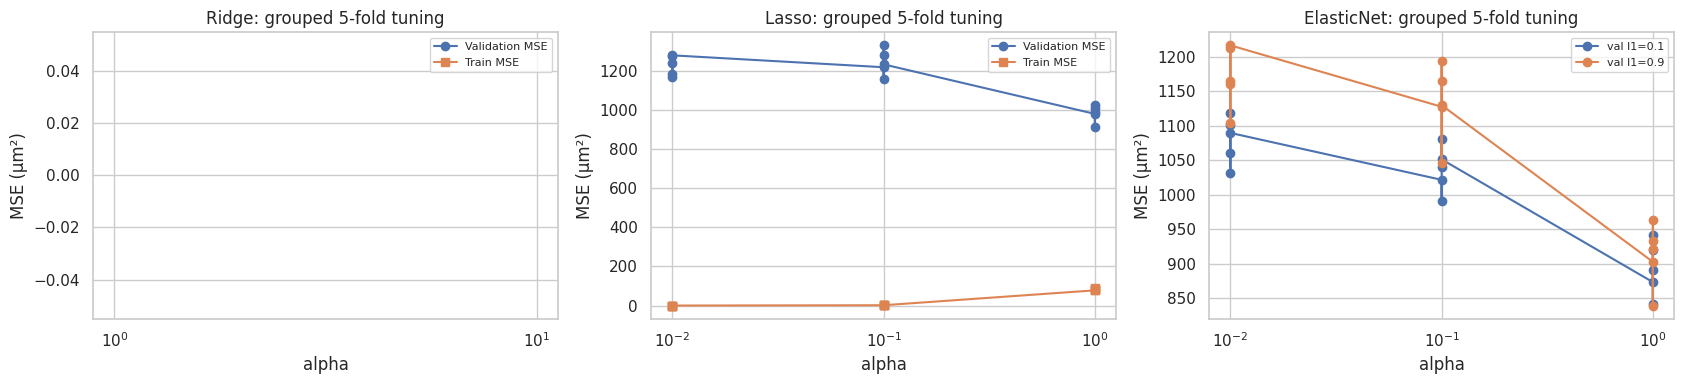

In [12]:
if FEATURE_READY:
    # CV curves: train and validation MSE by hyperparameter (diagnostic for overfitting).
    if cv_tables:
        all_grid = pd.concat(cv_tables, ignore_index=True)
        fig, axes = plt.subplots(1, 3, figsize=(17, 4))
        for ax, model_name in zip(axes, ["Ridge", "Lasso", "ElasticNet"]):
            sub = all_grid[all_grid.model == model_name].copy()
            if sub.empty:
                ax.set_visible(False); continue
            if model_name == "ElasticNet":
                sub["alpha"] = sub["param_regressor__estimator__alpha"].astype(float)
                sub["l1_ratio"] = sub["param_regressor__estimator__l1_ratio"].astype(float)
                for ratio, g in sub.groupby("l1_ratio"):
                    g = g.sort_values("alpha")
                    ax.plot(g.alpha, -g.mean_test_score, marker="o", label=f"val l1={ratio}")
                ax.set_xscale("log"); ax.set_xlabel("alpha"); ax.legend(fontsize=8)
            else:
                sub["alpha"] = sub["param_regressor__estimator__alpha"].astype(float)
                sub = sub.sort_values("alpha")
                ax.plot(sub.alpha, -sub.mean_test_score, marker="o", label="Validation MSE")
                ax.plot(sub.alpha, -sub.mean_train_score, marker="s", label="Train MSE")
                ax.set_xscale("log"); ax.set_xlabel("alpha"); ax.legend(fontsize=8)
            ax.set_title(f"{model_name}: grouped 5-fold tuning")
            ax.set_ylabel("MSE (µm²)")
        plt.tight_layout(); plt.show()
else:
    print("Dilewati: fitur tidak tersedia; jalankan ulang setelah menambahkan checkpoint dan source code.")

## 10. Evaluasi OOF pasien

Metrik utama dihitung dari gabungan prediksi out-of-fold untuk seluruh mata dan 12 sektor; setiap pasien diprediksi oleh model yang tidak dilatih dengan data pasien tersebut. Hasil per jam ikut dilaporkan.


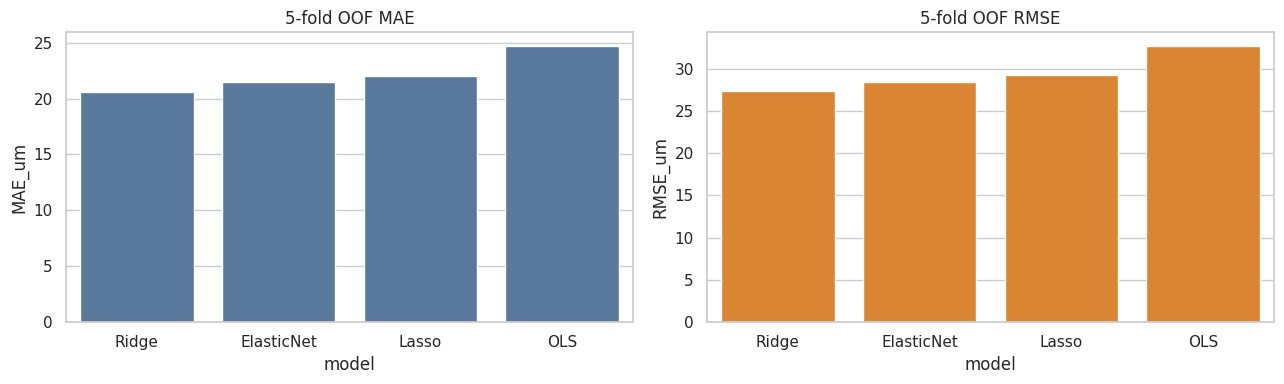

model,ElasticNet,Lasso,OLS,Ridge
clock_hour,,,,
1,25.43,26.57,28.21,25.42
2,15.85,15.49,17.25,15.95
3,13.50,13.95,15.71,12.71
4,15.59,15.90,18.82,14.53
5,29.98,31.02,34.08,29.61
6,26.70,26.73,30.82,26.02
7,26.02,27.93,30.05,24.16
8,20.55,20.83,23.27,18.40
9,18.41,19.31,22.85,15.66


In [13]:
if FEATURE_READY:
    fig, ax = plt.subplots(1,2,figsize=(13,4))
    sns.barplot(data=overall_results,x="model",y="MAE_um",ax=ax[0],color="#4C78A8"); ax[0].set_title("5-fold OOF MAE")
    sns.barplot(data=overall_results,x="model",y="RMSE_um",ax=ax[1],color="#F58518"); ax[1].set_title("5-fold OOF RMSE")
    plt.tight_layout(); plt.show()
    display(sector_results.pivot(index="clock_hour",columns="model",values="MAE_um").round(2))
else:
    print("Dilewati: fitur tidak tersedia.")

### Ketidakpastian metrik OOF pada level pasien

Bootstrap mengambil ulang pasien (bukan mata), agar dua mata dari pasien yang sama tetap satu klaster.


In [14]:
if FEATURE_READY:
    # Bootstrap berbasis pasien pada prediksi OOF; kedua mata pasien tetap ikut bersama.
    rng=np.random.default_rng(SEED); unique_patients=np.unique(groups); boot_rows=[]
    for b in range(1000):
        sampled=rng.choice(unique_patients,size=len(unique_patients),replace=True)
        idx=np.concatenate([np.flatnonzero(groups==pid) for pid in sampled])
        for name,pred in oof_predictions.items(): boot_rows.append({"bootstrap":b,"model":name,**regression_metrics(Y_all[idx],pred[idx])})
    boot_df=pd.DataFrame(boot_rows); ci_rows=[]
    for name,pred in oof_predictions.items():
        point=regression_metrics(Y_all,pred)
        for metric in ["MAE_um","RMSE_um","R2"]:
            vals=boot_df.loc[boot_df.model==name,metric]
            ci_rows.append({"model":name,"metric":metric,"estimate":point[metric],"ci_2.5":vals.quantile(.025),"ci_97.5":vals.quantile(.975)})
    bootstrap_ci=pd.DataFrame(ci_rows); display(bootstrap_ci)
    bootstrap_ci.to_csv(OUTPUT_DIR/"ets_oof_patient_bootstrap_ci.csv",index=False)
else: print("Dilewati: fitur tidak tersedia.")

,model,metric,estimate,ci_2.5,ci_97.5
0,OLS,MAE_um,24.684590,23.089412,26.368749
1,OLS,RMSE_um,32.644848,30.333135,34.991319
2,OLS,R2,0.419619,0.325477,0.497879
3,Ridge,MAE_um,20.628771,19.314603,21.962974
4,Ridge,RMSE_um,27.380614,25.275570,29.528165
5,Ridge,R2,0.591709,0.533813,0.645877
6,Lasso,MAE_um,22.053619,20.691068,23.455766
7,Lasso,RMSE_um,29.234386,27.109736,31.433277
8,Lasso,R2,0.534551,0.465176,0.594237
9,ElasticNet,MAE_um,21.464231,20.148877,22.809594


## 11. Visualisasi evaluasi OOF

Grafik meliputi metrik per jam, nilai aktual vs prediksi, dan residual berdasarkan prediksi OOF.


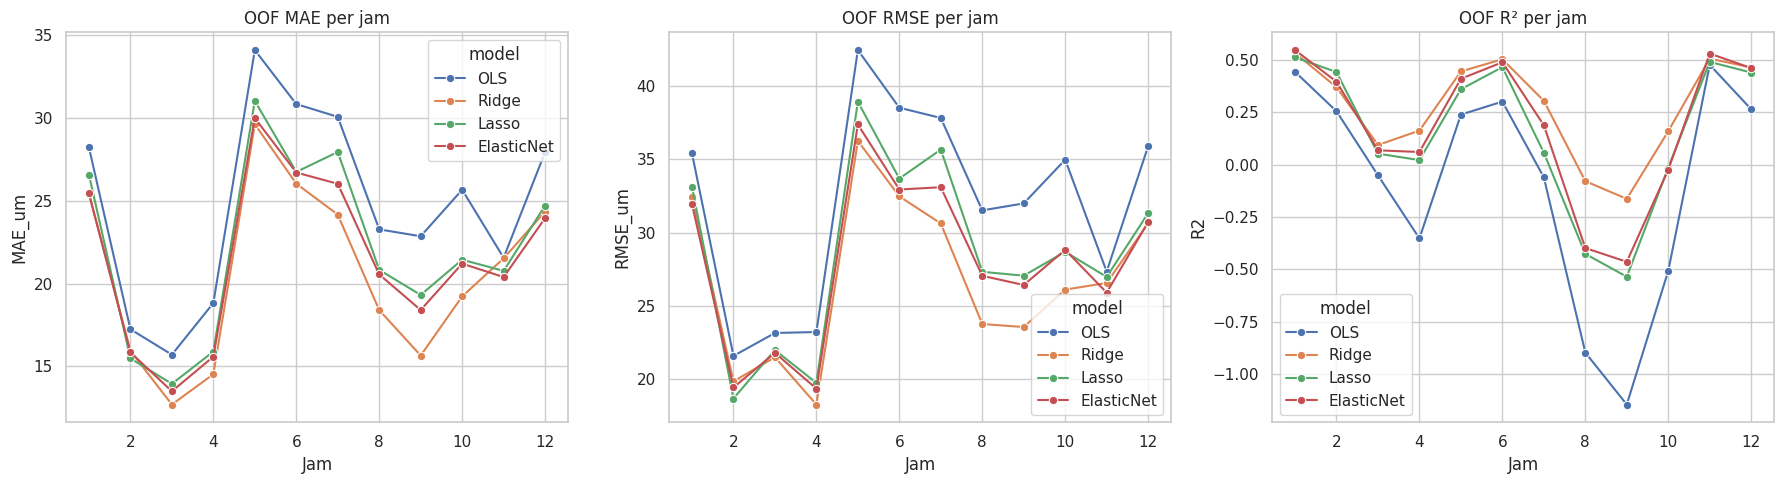

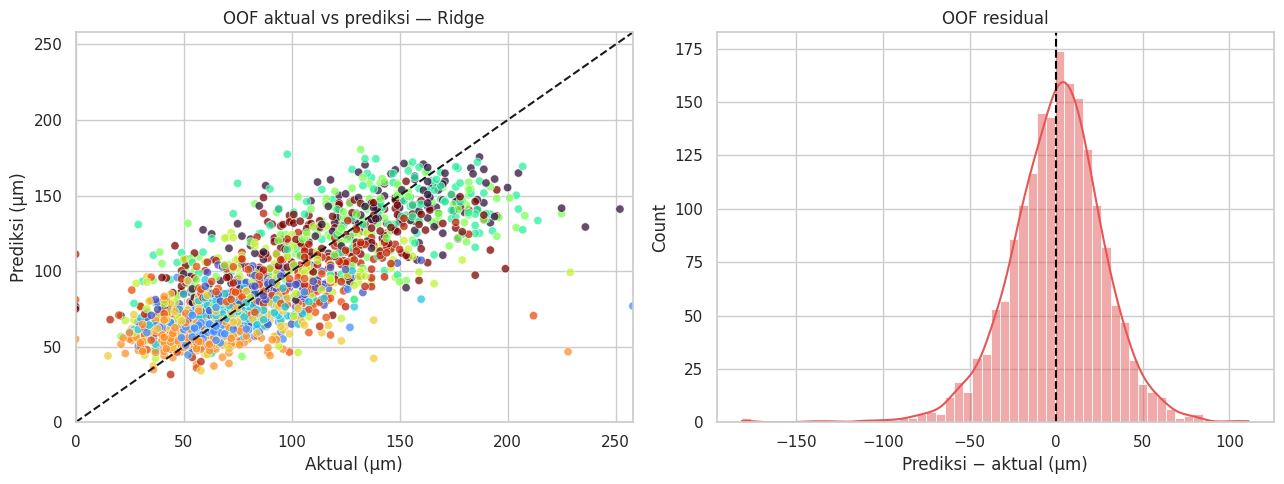

In [15]:
if FEATURE_READY:
    fig,ax=plt.subplots(1,3,figsize=(18,5))
    for axis,metric,title in zip(ax,["MAE_um","RMSE_um","R2"],["OOF MAE per jam","OOF RMSE per jam","OOF R² per jam"]):
        sns.lineplot(data=sector_results,x="clock_hour",y=metric,hue="model",marker="o",ax=axis)
        axis.set_title(title); axis.set_xlabel("Jam"); axis.set_ylabel(metric)
    plt.tight_layout(); plt.show()
    fig,ax=plt.subplots(1,2,figsize=(13,5))
    sns.scatterplot(x=Y_all.reshape(-1),y=best_pred.reshape(-1),hue=np.tile(np.arange(1,13),len(Y_all)),palette="turbo",ax=ax[0],legend=False,alpha=.75)
    lims=[min(Y_all.min(),best_pred.min()),max(Y_all.max(),best_pred.max())]; ax[0].plot(lims,lims,"k--"); ax[0].set_xlim(lims); ax[0].set_ylim(lims)
    ax[0].set_title(f"OOF aktual vs prediksi — {best_name}"); ax[0].set_xlabel("Aktual (µm)"); ax[0].set_ylabel("Prediksi (µm)")
    sns.histplot((best_pred-Y_all).reshape(-1),kde=True,ax=ax[1],color="#E45756"); ax[1].axvline(0,color="black",linestyle="--")
    ax[1].set_title("OOF residual"); ax[1].set_xlabel("Prediksi − aktual (µm)"); plt.tight_layout(); plt.show()
else: print("Dilewati: fitur tidak tersedia.")

## 12. Simpan prediksi dan hasil

Folder `rnfl_ets_outputs` berisi manifest 5-fold, audit pairing, sumber dan matriks fitur, tuning model dasar, metrik/prediksi OOF, interval bootstrap pasien, perbandingan ensemble/augmentasi, dan kurva pembelajaran bandit. Unduh dari panel Output Kaggle setelah Run All selesai.


In [16]:
if FEATURE_READY:
    # Seluruh prediksi OOF: tiap pasien diprediksi oleh model yang tidak pernah melatih pasien tersebut.
    print("Prediksi OOF:",OUTPUT_DIR/"ets_oof_predictions.csv")
    print("Metrik OOF:",OUTPUT_DIR/"ets_oof_overall_metrics.csv")
    print("Metrik per sektor:",OUTPUT_DIR/"ets_oof_metrics_by_clock_hour.csv")
    print("Manifest fold:",OUTPUT_DIR/"patient_groupkfold_manifest.csv")
    for p in sorted(OUTPUT_DIR.iterdir()): print(p.name,f"({p.stat().st_size/1024:.1f} KB)")
else: print("Dilewati: fitur tidak tersedia.")

Prediksi OOF: /kaggle/working/rnfl_ets_outputs/ets_oof_predictions.csv
Metrik OOF: /kaggle/working/rnfl_ets_outputs/ets_oof_overall_metrics.csv
Metrik per sektor: /kaggle/working/rnfl_ets_outputs/ets_oof_metrics_by_clock_hour.csv
Manifest fold: /kaggle/working/rnfl_ets_outputs/patient_groupkfold_manifest.csv
ets_bandit_learning_curve_by_fold.csv (5.8 KB)
ets_bandit_learning_curve_summary.csv (0.9 KB)
ets_cohort_audit.csv (0.2 KB)
ets_ensemble_fold_metrics.csv (2.1 KB)
ets_ensemble_oof_metrics.csv (0.5 KB)
ets_ensemble_oof_predictions.csv (131.0 KB)
ets_ensemble_paired_bootstrap.csv (19.7 KB)
ets_groupkfold_gridsearch_all.csv (21.1 KB)
ets_groupkfold_tuning_by_fold.csv (1.7 KB)
ets_oof_metrics_by_clock_hour.csv (5.0 KB)
ets_oof_overall_metrics.csv (0.4 KB)
ets_oof_patient_bootstrap_ci.csv (0.8 KB)
ets_oof_predictions.csv (191.5 KB)
feature_source.txt (0.0 KB)
features_augmented_photometric.npy (608.1 KB)
features_original.npy (608.1 KB)
fold_validation_metrics.csv (2.1 KB)
fundus_oct_pa

## Interpretasi, diskusi, dan bahan presentasi ETS (15 menit + 5 menit tanya jawab)

1. **Latar belakang dan manfaat (2 menit):** target adalah RNFL 12 jam dari fundus. Jelaskan potensi skrining dan batas bahwa prediksi tidak menggantikan OCT atau keputusan dokter.
2. **Data dan akuisisi (3 menit):** tampilkan jumlah pasien/mata, sumber CSV/foto, contoh pasangan fundus–OCT, jumlah yang tersisih, audit duplikasi/label hilang, dan GroupKFold pasien. Jelaskan bahwa tanggal foto serta OCT signal strength belum tersedia.
3. **Augmentasi (2 menit):** brightness/contrast/saturation ±10%, hanya train; label tetap, tanpa flip untuk menjaga orientasi. Bandingkan baris `Ensemble` dan `Ensemble + augmentasi` pada `ets_ensemble_oof_metrics.csv`. Jika MAE tidak membaik, laporkan apa adanya.
4. **Ensemble (2 menit):** Ridge menangkap tren linear; ExtraTrees menangkap nonlinieritas. Rata-rata dua prediksi dibandingkan dengan masing-masing model pada fold yang sama. Lihat MAE, RMSE, R² dan CI perbaikan MAE berbasis bootstrap pasien.
5. **Reinforcement/bandit (2 menit):** UCB1 memilih antara uncertainty, diversity, random berdasarkan reward penurunan MAE di holdout train. Tampilkan kurva MAE fold luar vs anggaran pasien berlabel serta aksi yang dipilih. Bandingkan kebijakan random. Tambahan data tidak menjamin peningkatan pada setiap putaran; reward yang bising dan cohort kecil dapat membuat bandit kalah dari random.
6. **Diskusi (4 menit):** sumber galat utama ialah pairing foto–OCT yang tidak memiliki tanggal, variasi kualitas foto, OCR/label RNFL, diagnosis tidak seimbang, serta ukuran sampel. Data augmentasi fotometrik tidak menciptakan pasien baru. Ensemble menambah waktu komputasi; RETFound memerlukan checkpoint dan GPU. Fitur sederhana adalah baseline untuk menjalankan pipeline, bukan replikasi Chen. Untuk pengembangan: review pairing manual, QC klinis, evaluasi eksternal lintas fasilitas, dan uji kebijakan akuisisi pada kohort lebih besar.

**Catatan kontribusi individu:** kriteria commit GitHub di slide ETS adalah administrasi kelompok. Lakukan commit pekerjaan tiap anggota pada repository GitHub kelompok dan simpan bukti kontribusinya; notebook tidak dapat membuat commit untuk anggota lain.

**Batas replikasi:** fitur pooled RETFound dapat berdimensi 1024, sedangkan paper menyebut latent vector 128 tanpa menjelaskan proyeksinya. Normalisasi jam OD mengikuti asumsi konvensi Chen; verifikasi dengan definisi metadata sebelum melaporkan angka. Semua prediksi evaluasi utama OOF dikelompokkan berdasarkan pasien. Pilih klaim performa berdasarkan angka yang benar-benar muncul setelah Run All, bukan dari contoh atau teks ini.